# Sequential Refinement LDM

## Architecture

**Stage 1**: 기존 latent_diffusion.py 사용 (1 CT → 1 Draft)  
**Stage 2**: Refiner (context window에서 top 5 선택)

---

## Pipeline

1. **Phase 1**: Draft Generation (기존 LDM으로 모든 CT → Draft)
2. **Phase 2**: Confidence Calculation (각 draft의 quality score)
3. **Phase 3**: Refiner Training (top 5 선택 후 refinement)

In [1]:
import sys
import os
from pathlib import Path
import warnings
import json
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings('ignore')

print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

/home/youkyoung/.conda/envs/med/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu124
CUDA Available: True


In [2]:
CFG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "seed": 42,
    
    # Paths
    "data_root": "../data/processed_with_skullstrip",
    "ldm_checkpoint": "./ckpt_ct2mri_b0_ldm_strip/last.pt",
    
    # Phase 1: Draft generation
    "draft_output_dir": "./draft_results",
    "ddim_steps": 200,
    "ddim_eta": 0.0,
    
    # Phase 2: Confidence
    "confidence_file": "./confidences.json",
    "confidence_samples": 3,
    
    # Phase 3: Refiner
    "img_size": 256,
    "train_ratio": 0.9,
    "batch_size": 16,
    "num_workers": 4,
    "epochs": 100,
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "grad_clip": 1.0,
    "confidence_threshold": 0.7,
    "use_mixed_precision": True,
    
    # Save
    "save_dir": "./ckpt_refiner",
    "save_every": 5,
}

torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])

Path(CFG["draft_output_dir"]).mkdir(parents=True, exist_ok=True)
Path(CFG["save_dir"]).mkdir(parents=True, exist_ok=True)

print("="*80)
print("Configuration")
print("="*80)
for k, v in CFG.items():
    print(f"  {k:30s}: {v}")
print("="*80)

Configuration
  device                        : cuda
  seed                          : 42
  data_root                     : ../data/processed_with_skullstrip
  ldm_checkpoint                : ./ckpt_ct2mri_b0_ldm_strip/last.pt
  draft_output_dir              : ./draft_results
  ddim_steps                    : 200
  ddim_eta                      : 0.0
  confidence_file               : ./confidences.json
  confidence_samples            : 3
  img_size                      : 256
  train_ratio                   : 0.9
  batch_size                    : 16
  num_workers                   : 4
  epochs                        : 100
  lr                            : 0.0001
  weight_decay                  : 0.0001
  grad_clip                     : 1.0
  confidence_threshold          : 0.7
  use_mixed_precision           : True
  save_dir                      : ./ckpt_refiner
  save_every                    : 5


In [3]:
# Add LDM path
ldm_path = os.path.expanduser('~/CT2MRI/diffusion_model/ldm')
if ldm_path not in sys.path:
    sys.path.insert(0, ldm_path)
print(f"Added to path: {ldm_path}")

# Imports
from ldm.modules.diffusionmodules.openaimodel import UNetModel
from ldm.modules.diffusionmodules.util import (
    make_beta_schedule,
    make_ddim_timesteps,
    make_ddim_sampling_parameters
)
from ldm.util import instantiate_from_config
from ldm.models.autoencoder import AutoencoderKL
from omegaconf import OmegaConf

print("✓ LDM modules imported")

Added to path: /home/youkyoung/CT2MRI/diffusion_model/ldm
✓ LDM modules imported


In [4]:
def build_vae(vae_config_path, vae_ckpt_path, device):
    """
    Build VAE from config and checkpoint
    """
    print(f"Loading VAE...")
    print(f"  Config: {vae_config_path}")
    print(f"  Checkpoint: {vae_ckpt_path}")
    
    # Load config
    raw_config = OmegaConf.load(vae_config_path)
    config_dict = OmegaConf.to_container(raw_config, resolve=True)
    
    # Get model config
    model_config = config_dict.get("model", {})
    target = model_config.get("target", "")
    
    if "AutoencoderKL" not in target:
        raise NotImplementedError(f"Only AutoencoderKL supported, got: {target}")
    
    # Instantiate
    vae = instantiate_from_config(model_config)
    vae.to(device)
    
    # Load checkpoint
    ckpt = torch.load(vae_ckpt_path, map_location="cpu")
    state_dict = ckpt.get("state_dict", ckpt)
    vae.load_state_dict(state_dict, strict=False)
    vae.eval()
    
    # Freeze
    for param in vae.parameters():
        param.requires_grad = False
    
    print("✓ VAE loaded and frozen")
    
    return vae

print("✓ build_vae function defined")

✓ build_vae function defined


In [5]:
print("\n" + "="*80)
print("Loading LDM Checkpoint")
print("="*80)

# Load checkpoint
ckpt = torch.load(CFG["ldm_checkpoint"], map_location="cpu")
cfg = ckpt["cfg"]

print(f"\nCheckpoint info:")
print(f"  Image size: {cfg['img_size']}")
print(f"  Timesteps: {cfg['num_timesteps']}")
print(f"  Beta schedule: {cfg['beta_schedule']}")

# Build VAE
vae_config = cfg["vae"]["config"]
vae_ckpt = cfg["vae"]["ckpt"]

vae = build_vae(vae_config, vae_ckpt, CFG["device"])

# Get latent dimensions
# dummy_img = torch.randn(1, 1, cfg["img_size"], cfg["img_size"]).to(CFG["device"])
dummy_img = torch.randn(1, 3, cfg["img_size"], cfg["img_size"]).to(CFG["device"])
dummy_img = dummy_img * 2 - 1  # [-1, 1]
with torch.no_grad():
    dummy_latent = vae.encode(dummy_img).sample() * 0.18215

z_channels = dummy_latent.shape[1]
lat_h, lat_w = dummy_latent.shape[2], dummy_latent.shape[3]

print(f"\nLatent space:")
print(f"  Channels: {z_channels}")
print(f"  Spatial: {lat_h} x {lat_w}")

# Build U-Net
lu_cfg = cfg["latent_unet"]
in_channels = z_channels + lu_cfg["cond_channels"]
out_channels = z_channels

unet = UNetModel(
    image_size=lat_h,
    in_channels=in_channels,
    out_channels=out_channels,
    model_channels=lu_cfg["model_channels"],
    num_res_blocks=lu_cfg["num_res_blocks"],
    channel_mult=tuple(lu_cfg["channel_mult"]),
    attention_resolutions=tuple(lu_cfg.get("attention_resolutions", (16,))),
    num_heads=lu_cfg.get("num_heads", -1),
    num_head_channels=lu_cfg.get("num_head_channels", 64),
    num_heads_upsample=lu_cfg.get("num_heads_upsample", -1),
    dropout=lu_cfg["dropout"],
    conv_resample=True,
    dims=2,
    num_classes=None,
    use_checkpoint=lu_cfg["use_checkpoint"],
    use_fp16=lu_cfg["use_fp16"],
    use_scale_shift_norm=lu_cfg["use_scale_shift_norm"],
    resblock_updown=lu_cfg["resblock_updown"],
    use_new_attention_order=lu_cfg["use_new_attention_order"],
    use_spatial_transformer=lu_cfg["use_spatial_transformer"],
    transformer_depth=lu_cfg["transformer_depth"],
    context_dim=lu_cfg["context_dim"],
    n_embed=lu_cfg["n_embed"],
    legacy=lu_cfg["legacy"]
).to(CFG["device"])

unet.eval()

# Build condition encoder
class CTCondEncoder(nn.Module):
    def __init__(self, cond_channels=1):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 3, 2, 1),
            nn.SiLU(),
            nn.Conv2d(32, 64, 3, 2, 1),
            nn.SiLU(),
            nn.Conv2d(64, cond_channels, 1)
        )
    
    def forward(self, x):
        return self.enc(x)

cond_enc = CTCondEncoder(cond_channels=lu_cfg["cond_channels"]).to(CFG["device"])
cond_enc.eval()

# Load weights
unet.load_state_dict(ckpt["model"], strict=True)
cond_enc.load_state_dict(ckpt["cond_enc"], strict=True)

# Apply EMA if available
if ckpt.get("ema", None) is not None:
    print("\nApplying EMA weights...")
    with torch.no_grad():
        for name, param in unet.named_parameters():
            if param.requires_grad and name in ckpt["ema"]:
                param.data.copy_(ckpt["ema"][name].to(param.device))
    print("✓ EMA applied")

# Freeze
for param in unet.parameters():
    param.requires_grad = False
for param in cond_enc.parameters():
    param.requires_grad = False

print("\n✓ U-Net and Condition Encoder loaded and frozen")
print("="*80)


Loading LDM Checkpoint

Checkpoint info:
  Image size: 256
  Timesteps: 1000
  Beta schedule: cosine
Loading VAE...
  Config: autoencoder_kl_64x64x3.yaml
  Checkpoint: ae_model.ckpt
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 3, 64, 64) = 12288 dimensions.
making attention of type 'vanilla' with 512 in_channels
loaded pretrained LPIPS loss from taming/modules/autoencoder/lpips/vgg.pth
✓ VAE loaded and frozen

Latent space:
  Channels: 3
  Spatial: 64 x 64

Applying EMA weights...
✓ EMA applied

✓ U-Net and Condition Encoder loaded and frozen


In [6]:
# Build schedule
num_timesteps = cfg["num_timesteps"]
beta_schedule = cfg["beta_schedule"]

betas = torch.from_numpy(
    make_beta_schedule(beta_schedule, num_timesteps)
).float().to(CFG["device"])

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

sched_dict = {
    "betas": betas,
    "alphas": alphas,
    "alphas_cumprod": alphas_cumprod
}

print("Diffusion schedule:")
print(f"  Timesteps: {num_timesteps}")
print(f"  Beta schedule: {beta_schedule}")
print(f"  Beta range: [{betas.min():.6f}, {betas.max():.6f}]")

Diffusion schedule:
  Timesteps: 1000
  Beta schedule: cosine
  Beta range: [0.000041, 0.999000]


In [7]:
@torch.no_grad()
def sample_ddim_latent(unet, cond_enc, vae, ct_m11, sched_dict, ddim_steps=200, eta=0.0, device="cpu"):
    """
    DDIM sampling in latent space
    
    Args:
        unet: U-Net model
        cond_enc: Condition encoder
        vae: VAE model
        ct_m11: CT image in [-1, 1], shape (B, 1, H, W)
        sched_dict: Schedule dictionary
        ddim_steps: Number of DDIM steps
        eta: DDIM eta parameter
        device: Device
    
    Returns:
        pred_m11: Predicted MRI in [-1, 1], shape (B, 1, H, W)
    """
    B = ct_m11.size(0)
    
    # Encode CT condition
    ct_cond = cond_enc(ct_m11)
    ct_m11_3ch = ct_m11.repeat(1, 3, 1, 1)  # (B, 1, H, W) → (B, 3, H, W)
    
    # Get latent shape
    with torch.no_grad():
        test_latent = vae.encode(ct_m11_3ch).sample() * 0.18215
    
    Cz = test_latent.shape[1]
    lat_h, lat_w = test_latent.shape[2], test_latent.shape[3]
    
    # Random noise
    z = torch.randn(B, Cz, lat_h, lat_w, device=device)
    
    # DDIM timesteps
    ts = np.array(
        make_ddim_timesteps('uniform', ddim_steps, len(sched_dict['betas']))
    ) - 1
    
    sigmas, alphas, alphas_prev = make_ddim_sampling_parameters(
        sched_dict['alphas_cumprod'].cpu().numpy(),
        ts,
        eta
    )
    
    sigmas = torch.from_numpy(sigmas).float().to(device)
    alphas = torch.from_numpy(alphas).float().to(device)
    alphas_prev = torch.from_numpy(alphas_prev).float().to(device)
    
    # DDIM loop
    for i in reversed(range(len(ts))):
        t = int(ts[i])
        t_batch = torch.full((B,), t, device=device, dtype=torch.long)
        
        # Predict noise
        eps = unet(torch.cat([z, ct_cond], dim=1).float(), t_batch)
        
        # DDIM update
        a_t = alphas[i]
        a_prev = alphas_prev[i]
        s_t = sigmas[i]
        
        # Predict x0
        z0 = (z - torch.sqrt(1.0 - a_t) * eps) / torch.sqrt(a_t)
        
        # Direction to xt
        dir_term = torch.sqrt(1.0 - a_prev - s_t**2) * eps
        
        # Random noise
        noise = s_t * torch.randn_like(z) if i > 0 else 0.0
        
        # Update
        z = torch.sqrt(a_prev) * z0 + dir_term + noise
    
    # Decode
    pred_m11_3ch = vae.decode(z / 0.18215)
    pred_m11 = pred_m11_3ch.mean(dim=1, keepdim=True)  # (B, 3, H, W) → (B, 1, H, W)
    
    return pred_m11

print("✓ DDIM sampler defined")

✓ DDIM sampler defined


In [8]:
def load_image(path, size=256):
    """Load and preprocess image to [0, 1]"""
    img = Image.open(path).convert('L')
    img = img.resize((size, size), Image.BICUBIC)
    return np.array(img, dtype=np.float32) / 255.0

def save_image(tensor, path):
    """Save tensor as image"""
    if tensor.dim() == 4:
        tensor = tensor.squeeze(0)
    if tensor.dim() == 3:
        tensor = tensor.squeeze(0)
    
    # [-1, 1] → [0, 1]
    if tensor.min() < 0:
        tensor = (tensor + 1) / 2
    
    tensor = tensor.clamp(0, 1)
    img_array = (tensor.cpu().numpy() * 255).astype(np.uint8)
    
    img = Image.fromarray(img_array, mode='L')
    img.save(path)

print("✓ Utility functions defined")

✓ Utility functions defined


In [9]:
def generate_all_drafts(unet, cond_enc, vae, sched_dict, data_root, output_dir, 
                        ddim_steps=200, ddim_eta=0.0, device="cuda"):
    """Generate drafts for all CT images"""
    
    print("\n" + "="*80)
    print("Phase 1: Draft Generation")
    print("="*80)
    
    data_root = Path(data_root)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Collect CT files
    ct_files = []
    for group in ['bleed', 'non_bleed']:
        group_dir = data_root / group
        if not group_dir.exists():
            continue
        
        for patient_dir in sorted(group_dir.iterdir()):
            if not patient_dir.is_dir():
                continue
            
            ct_dir = patient_dir / 'ct_axial'
            if not ct_dir.exists():
                continue
            
            for ct_file in sorted(ct_dir.glob('*.png')):
                ct_files.append({
                    'group': group,
                    'patient': patient_dir.name,
                    'slice_name': ct_file.stem,
                    'path': ct_file
                })
    
    print(f"Found {len(ct_files)} CT slices\n")
    
    # Generate drafts
    for item in tqdm(ct_files, desc="Generating drafts"):
        draft_path = output_dir / item['group'] / item['patient'] / f"{item['slice_name']}.png"
        
        if draft_path.exists():
            continue
        
        # Load CT
        ct = load_image(item['path'])
        ct_tensor = torch.from_numpy(ct).unsqueeze(0).unsqueeze(0).to(device)
        ct_tensor = ct_tensor * 2 - 1  # [0,1] → [-1,1]
        
        # Generate draft
        with torch.no_grad():
            draft = sample_ddim_latent(
                unet, cond_enc, vae, ct_tensor, sched_dict,
                ddim_steps=ddim_steps, eta=ddim_eta, device=device
            )
        
        # Save
        draft_path.parent.mkdir(parents=True, exist_ok=True)
        save_image(draft, draft_path)
    
    print("\n✓ Phase 1 complete")
    print(f"  Drafts saved to: {output_dir}")
    print("="*80)

print("✓ generate_all_drafts function defined")

✓ generate_all_drafts function defined


In [10]:
def calculate_confidences(unet, cond_enc, vae, sched_dict, data_root, output_file,
                         num_samples=3, ddim_steps=200, device="cuda"):
    """Calculate confidence scores for all drafts"""
    
    print("\n" + "="*80)
    print("Phase 2: Confidence Calculation")
    print("="*80)
    
    data_root = Path(data_root)
    
    # Collect CT files
    ct_files = []
    for group in ['bleed', 'non_bleed']:
        group_dir = data_root / group
        if not group_dir.exists():
            continue
        
        for patient_dir in sorted(group_dir.iterdir()):
            if not patient_dir.is_dir():
                continue
            
            ct_dir = patient_dir / 'ct_axial'
            if not ct_dir.exists():
                continue
            
            for ct_file in sorted(ct_dir.glob('*.png')):
                ct_files.append({
                    'group': group,
                    'patient': patient_dir.name,
                    'slice_name': ct_file.stem,
                    'path': ct_file
                })
    
    print(f"Found {len(ct_files)} CT slices\n")
    
    confidences = {}
    
    for item in tqdm(ct_files, desc="Computing confidences"):
        key = f"{item['group']}/{item['patient']}/{item['slice_name']}"
        
        # Load CT
        ct = load_image(item['path'])
        ct_tensor = torch.from_numpy(ct).unsqueeze(0).unsqueeze(0).to(device)
        ct_tensor = ct_tensor * 2 - 1
        
        # Multiple sampling
        samples = []
        with torch.no_grad():
            for _ in range(num_samples):
                sample = sample_ddim_latent(
                    unet, cond_enc, vae, ct_tensor, sched_dict,
                    ddim_steps=ddim_steps, eta=0.0, device=device
                )
                samples.append(sample.cpu().numpy())
        
        # Compute confidence
        samples_array = np.array(samples)
        variance = samples_array.var(axis=0).mean()
        confidence = float(np.exp(-variance * 10.0))
        
        confidences[key] = confidence
    
    # Save
    with open(output_file, 'w') as f:
        json.dump(confidences, f, indent=2)
    
    print(f"\n✓ Phase 2 complete")
    print(f"  Confidences saved to: {output_file}")
    
    # Statistics
    conf_values = list(confidences.values())
    print(f"\nStatistics:")
    print(f"  Mean: {np.mean(conf_values):.4f}")
    print(f"  Std:  {np.std(conf_values):.4f}")
    print(f"  Min:  {np.min(conf_values):.4f}")
    print(f"  Max:  {np.max(conf_values):.4f}")
    print("="*80)

print("✓ calculate_confidences function defined")

✓ calculate_confidences function defined


In [38]:
class RefinerDataset(Dataset):
    def __init__(self, data_root, draft_dir, confidence_file, mode='train', 
                 train_ratio=0.9, img_size=256):
        self.data_root = Path(data_root)
        self.draft_dir = Path(draft_dir)
        self.img_size = img_size
        self.mode = mode
        
        # Load confidences
        with open(confidence_file, 'r') as f:
            self.confidences = json.load(f)
        
        self.samples = self._collect_samples(train_ratio)
        
        print(f"[{mode.upper()}] Dataset: {len(self.samples)} samples")
    
    def _collect_samples(self, train_ratio):
        samples = []
        
        for group in ['bleed', 'non_bleed']:
            group_dir = self.data_root / group
            if not group_dir.exists():
                continue
            
            for patient_dir in sorted(group_dir.iterdir()):
                if not patient_dir.is_dir():
                    continue
                
                patient = patient_dir.name
                ct_dir = patient_dir / 'ct_axial'
                mri_dir = patient_dir / 'mri_b0_axial'
                
                if not (ct_dir.exists() and mri_dir.exists()):
                    continue
                
                ct_files = sorted(ct_dir.glob('*.png'))
                mri_files = sorted(mri_dir.glob('*.png'))
                
                ct_dict = {f.stem: f for f in ct_files}
                mri_dict = {f.stem: f for f in mri_files}
                common = sorted(set(ct_dict.keys()) & set(mri_dict.keys()))
                
                for i, slice_name in enumerate(common):
                    draft_file = self.draft_dir / group / patient / f"{slice_name}.png"
                    if not draft_file.exists():
                        continue
                    
                    samples.append({
                        'group': group,
                        'patient': patient,
                        'slice_idx': i,
                        'slice_name': slice_name,
                        'total_slices': len(common),
                        'all_slices': common
                    })
        
        # Train/val split
        samples.sort(key=lambda x: x['patient'])
        patients = sorted(set(s['patient'] for s in samples))
        n_train = int(len(patients) * train_ratio)
        train_patients = set(patients[:n_train])
        
        if self.mode == 'train':
            return [s for s in samples if s['patient'] in train_patients]
        else:
            return [s for s in samples if s['patient'] not in train_patients]
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        group = sample['group']
        patient = sample['patient']
        center_idx = sample['slice_idx']
        slice_name = sample['slice_name']
        total = sample['total_slices']
        all_slices = sample['all_slices']
        
        # Context window
        if center_idx < 5:
            start, end = 0, min(center_idx + 6, total)
        elif center_idx >= total - 5:
            start, end = max(center_idx - 5, 0), total
        else:
            start, end = center_idx - 5, center_idx + 6
        
        # Load drafts + confidences
        drafts = []
        confs = []
        
        for i in range(start, end):
            slice_name_i = all_slices[i]
            
            draft_path = self.draft_dir / group / patient / f"{slice_name_i}.png"
            draft = load_image(draft_path, self.img_size)
            drafts.append(draft)
            
            key = f"{group}/{patient}/{slice_name_i}"
            conf = self.confidences.get(key, 0.5)
            confs.append(conf)
        
        # Select top 5
        confs = np.array(confs)
        if len(confs) >= 5:
            top_indices = np.argsort(confs)[-5:][::-1]
        else:
            top_indices = np.arange(len(confs))
        
        selected_drafts = [drafts[i] for i in top_indices]
        selected_confs = confs[top_indices]
        
        # Pad to 5
        while len(selected_drafts) < 5:
            selected_drafts.append(np.zeros_like(selected_drafts[0]))
            selected_confs = np.append(selected_confs, 0.0)
        
        # Load center CT and GT
        ct_path = self.data_root / group / patient / 'ct_axial' / f"{slice_name}.png"
        mri_path = self.data_root / group / patient / 'mri_b0_axial' / f"{slice_name}.png"
        
        ct_center = load_image(ct_path, self.img_size)
        mri_gt = load_image(mri_path, self.img_size)
        
        # Center confidence
        center_key = f"{group}/{patient}/{slice_name}"
        center_conf = self.confidences.get(center_key, 0.5)
        
        # To tensor
        selected_drafts_t = torch.stack([torch.from_numpy(d) for d in selected_drafts]).float()
        ct_center_t = torch.from_numpy(ct_center).unsqueeze(0).float()
        mri_gt_t = torch.from_numpy(mri_gt).unsqueeze(0).float()
        
        selected_drafts_t = selected_drafts_t * 2 - 1
        ct_center_t = ct_center_t * 2 - 1
        mri_gt_t = mri_gt_t * 2 - 1
        
        return {
            'selected_drafts': selected_drafts_t,
            'ct_center': ct_center_t,
            'mri_gt': mri_gt_t,
            'confidences': torch.from_numpy(selected_confs).float(),
            'center_conf': torch.tensor(center_conf).float(),
            # ⭐ 메타데이터 추가
            'patient': sample['patient'],
            'slice_name': sample['slice_name'],
            'group': sample['group'],
        }

print("✓ RefinerDataset defined")

✓ RefinerDataset defined


In [39]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, padding=1):
        super().__init__()
        self.depthwise = nn.Conv2d(in_ch, in_ch, kernel_size, stride, padding, groups=in_ch)
        self.pointwise = nn.Conv2d(in_ch, out_ch, 1)
    
    def forward(self, x):
        return self.pointwise(self.depthwise(x))


class ConvNeXtBlock(nn.Module):
    def __init__(self, channels, expansion=4):
        super().__init__()
        self.dwconv = nn.Conv2d(channels, channels, 7, 1, 3, groups=channels)
        self.norm = nn.LayerNorm(channels)
        self.pwconv1 = nn.Linear(channels, expansion * channels)
        self.act = nn.GELU()
        self.pwconv2 = nn.Linear(expansion * channels, channels)
        self.gamma = nn.Parameter(torch.ones(channels) * 1e-6)
    
    def forward(self, x):
        residual = x
        x = self.dwconv(x)
        x = x.permute(0, 2, 3, 1)
        x = self.norm(x)
        x = self.pwconv1(x)
        x = self.act(x)
        x = self.pwconv2(x)
        x = self.gamma * x
        x = x.permute(0, 3, 1, 2)
        return residual + x


class RefinerUNet(nn.Module):
    def __init__(self, in_channels, out_channels=1, base_channels=64):
        super().__init__()
        
        self.enc1 = nn.Sequential(
            DepthwiseSeparableConv(in_channels, base_channels),
            nn.GroupNorm(8, base_channels),
            nn.GELU(),
            ConvNeXtBlock(base_channels)
        )
        
        self.enc2 = nn.Sequential(
            nn.MaxPool2d(2),
            DepthwiseSeparableConv(base_channels, base_channels * 2),
            nn.GroupNorm(8, base_channels * 2),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 2)
        )
        
        self.enc3 = nn.Sequential(
            nn.MaxPool2d(2),
            DepthwiseSeparableConv(base_channels * 2, base_channels * 4),
            nn.GroupNorm(8, base_channels * 4),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 4)
        )
        
        self.bottleneck = nn.Sequential(
            nn.MaxPool2d(2),
            DepthwiseSeparableConv(base_channels * 4, base_channels * 8),
            nn.GroupNorm(8, base_channels * 8),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 8)
        )
        
        self.up3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, 2, 2)
        self.dec3 = nn.Sequential(
            DepthwiseSeparableConv(base_channels * 8, base_channels * 4),
            nn.GroupNorm(8, base_channels * 4),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 4)
        )
        
        self.up2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 2, 2)
        self.dec2 = nn.Sequential(
            DepthwiseSeparableConv(base_channels * 4, base_channels * 2),
            nn.GroupNorm(8, base_channels * 2),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 2)
        )
        
        self.up1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 2, 2)
        self.dec1 = nn.Sequential(
            DepthwiseSeparableConv(base_channels * 2, base_channels),
            nn.GroupNorm(8, base_channels),
            nn.GELU(),
            ConvNeXtBlock(base_channels)
        )
        
        self.out = nn.Conv2d(base_channels, out_channels, 1)
    
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], 1)
        d3 = self.dec3(d3)
        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], 1)
        d2 = self.dec2(d2)
        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], 1)
        d1 = self.dec1(d1)
        return self.out(d1)


class AdaptiveRefiner(nn.Module):
    def __init__(self, confidence_threshold=0.7):
        super().__init__()
        self.threshold = confidence_threshold
        
        # Context encoder: 5 → 256
        self.context_encoder = nn.Sequential(
            DepthwiseSeparableConv(5, 64),
            nn.GroupNorm(8, 64),
            nn.GELU(),
            ConvNeXtBlock(64),
            DepthwiseSeparableConv(64, 128),
            nn.GroupNorm(8, 128),
            nn.GELU(),
            ConvNeXtBlock(128),
            DepthwiseSeparableConv(128, 256),
            nn.GroupNorm(8, 256),
            nn.GELU(),
        )
        
        # Refiner: 258 → 1
        self.refiner = RefinerUNet(in_channels=258, out_channels=1, base_channels=64)
    
    def forward(self, selected_drafts, ct_center, center_conf):
        B = selected_drafts.shape[0]
        
        # Adaptive strategy
        use_center = (center_conf > self.threshold).float().view(B, 1, 1, 1)
        
        draft_center = selected_drafts[:, 0:1]
        neighbors_avg = selected_drafts.mean(dim=1, keepdim=True)
        
        draft_base = use_center * draft_center + (1 - use_center) * neighbors_avg
        
        # Context
        context = self.context_encoder(selected_drafts)
        
        # Refine
        refiner_input = torch.cat([draft_base, ct_center, context], dim=1)
        refined = self.refiner(refiner_input)
        
        return refined, draft_base

print("✓ Refiner models defined")

✓ Refiner models defined


In [40]:
class RefinementLoss(nn.Module):
    def __init__(self):
        super().__init__()
    
    def ssim(self, x, y, window_size=11):
        C1 = 0.01 ** 2
        C2 = 0.03 ** 2
        
        mu_x = F.avg_pool2d(x, window_size, 1, window_size // 2)
        mu_y = F.avg_pool2d(y, window_size, 1, window_size // 2)
        
        sigma_x = F.avg_pool2d(x ** 2, window_size, 1, window_size // 2) - mu_x ** 2
        sigma_y = F.avg_pool2d(y ** 2, window_size, 1, window_size // 2) - mu_y ** 2
        sigma_xy = F.avg_pool2d(x * y, window_size, 1, window_size // 2) - mu_x * mu_y
        
        ssim_n = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
        ssim_d = (mu_x ** 2 + mu_y ** 2 + C1) * (sigma_x + sigma_y + C2)
        
        return (ssim_n / ssim_d).mean()
    
    def forward(self, refined, draft_base, target, epoch=0):
        l1 = F.l1_loss(refined, target)
        l2 = F.mse_loss(refined, target)
        ssim_loss = 1.0 - self.ssim(refined, target)
        
        draft_error = F.l1_loss(draft_base, target, reduction='none').mean(dim=(1,2,3))
        refined_error = F.l1_loss(refined, target, reduction='none').mean(dim=(1,2,3))
        improve = F.relu(refined_error - draft_error + 0.01).mean()
        
        if epoch < 20:
            w = {'l1': 0.7, 'l2': 0.3, 'ssim': 0.0, 'improve': 0.0}
        elif epoch < 50:
            w = {'l1': 0.5, 'l2': 0.2, 'ssim': 0.2, 'improve': 0.1}
        else:
            w = {'l1': 0.4, 'l2': 0.2, 'ssim': 0.3, 'improve': 0.1}
        
        total = w['l1']*l1 + w['l2']*l2 + w['ssim']*ssim_loss + w['improve']*improve
        
        return {
            'total': total,
            'l1': l1,
            'l2': l2,
            'ssim': ssim_loss,
            'improvement': improve
        }


def train_epoch(model, loader, criterion, optimizer, scaler, epoch, device, grad_clip, use_amp):
    model.train()
    losses = defaultdict(list)
    stats = {'center': 0, 'neighbors': 0}
    
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}")
    
    for batch in pbar:
        selected_drafts = batch['selected_drafts'].to(device)
        ct_center = batch['ct_center'].to(device)
        mri_gt = batch['mri_gt'].to(device)
        center_conf = batch['center_conf'].to(device)
        
        optimizer.zero_grad()
        
        if use_amp:
            with autocast():
                refined, draft_base = model(selected_drafts, ct_center, center_conf)
                loss_dict = criterion(refined, draft_base, mri_gt, epoch)
                loss = loss_dict['total']
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            refined, draft_base = model(selected_drafts, ct_center, center_conf)
            loss_dict = criterion(refined, draft_base, mri_gt, epoch)
            loss = loss_dict['total']
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
        
        for k, v in loss_dict.items():
            losses[k].append(v.item())
        
        for conf in center_conf:
            stats['center' if conf.item() > model.threshold else 'neighbors'] += 1
        
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
    
    result = {k: np.mean(v) for k, v in losses.items()}
    result['strategy_stats'] = stats
    return result


@torch.no_grad()
def val_epoch(model, loader, criterion, epoch, device):
    model.eval()
    losses = defaultdict(list)
    stats = {'center': 0, 'neighbors': 0}
    
    for batch in tqdm(loader, desc="Validation"):
        selected_drafts = batch['selected_drafts'].to(device)
        ct_center = batch['ct_center'].to(device)
        mri_gt = batch['mri_gt'].to(device)
        center_conf = batch['center_conf'].to(device)
        
        refined, draft_base = model(selected_drafts, ct_center, center_conf)
        loss_dict = criterion(refined, draft_base, mri_gt, epoch)
        
        for k, v in loss_dict.items():
            losses[k].append(v.item())
        
        for conf in center_conf:
            stats['center' if conf.item() > model.threshold else 'neighbors'] += 1
    
    result = {k: np.mean(v) for k, v in losses.items()}
    result['strategy_stats'] = stats
    return result

print("✓ Loss and training functions defined")

✓ Loss and training functions defined


In [41]:
# dataset train / val 개수 세기
from pathlib import Path
from collections import defaultdict

data_root = Path("../data/processed_with_skullstrip")
train_ratio = 0.9

# Collect samples
samples = []
for group in ['bleed', 'non_bleed']:
    group_dir = data_root / group
    if not group_dir.exists():
        continue
    
    for patient_dir in sorted(group_dir.iterdir()):
        if not patient_dir.is_dir():
            continue
        
        patient = patient_dir.name
        ct_dir = patient_dir / 'ct_axial'
        mri_dir = patient_dir / 'mri_b0_axial'
        
        if not (ct_dir.exists() and mri_dir.exists()):
            continue
        
        ct_files = sorted(ct_dir.glob('*.png'))
        mri_files = sorted(mri_dir.glob('*.png'))
        
        # CT-MRI matching
        ct_dict = {f.stem: f for f in ct_files}
        mri_dict = {f.stem: f for f in mri_files}
        common = sorted(set(ct_dict.keys()) & set(mri_dict.keys()))
        
        for stem in common:
            samples.append({
                'group': group,
                'patient': patient,
                'slice': stem
            })

# Train/Val split by patient
patients = sorted(set(s['patient'] for s in samples))
n_train = int(len(patients) * train_ratio)
train_patients = set(patients[:n_train])

train_samples = [s for s in samples if s['patient'] in train_patients]
val_samples = [s for s in samples if s['patient'] not in train_patients]

# Statistics
print("="*80)
print("Dataset Statistics")
print("="*80)
print(f"\nTotal patients: {len(patients)}")
print(f"  Train patients: {len(train_patients)}")
print(f"  Val patients:   {len(patients) - len(train_patients)}")

print(f"\nTotal slices: {len(samples)}")
print(f"  Train slices: {len(train_samples)}")
print(f"  Val slices:   {len(val_samples)}")

# Group breakdown
train_by_group = defaultdict(int)
val_by_group = defaultdict(int)

for s in train_samples:
    train_by_group[s['group']] += 1
for s in val_samples:
    val_by_group[s['group']] += 1

print(f"\nTrain breakdown:")
for group, count in sorted(train_by_group.items()):
    print(f"  {group:15s}: {count:4d} slices")

print(f"\nVal breakdown:")
for group, count in sorted(val_by_group.items()):
    print(f"  {group:15s}: {count:4d} slices")

print("="*80)

Dataset Statistics

Total patients: 374
  Train patients: 336
  Val patients:   38

Total slices: 5910
  Train slices: 5321
  Val slices:   589

Train breakdown:
  bleed          : 3031 slices
  non_bleed      : 2290 slices

Val breakdown:
  non_bleed      :  589 slices


In [42]:
# Run Phase 1
generate_all_drafts(
    unet, cond_enc, vae, sched_dict,
    CFG["data_root"],
    CFG["draft_output_dir"],
    ddim_steps=CFG["ddim_steps"],
    ddim_eta=CFG["ddim_eta"],
    device=CFG["device"]
)


Phase 1: Draft Generation
Found 5910 CT slices



Generating drafts: 100%|██████████| 5910/5910 [00:00<00:00, 115542.87it/s]


✓ Phase 1 complete
  Drafts saved to: draft_results


In [43]:
# Run Phase 2
calculate_confidences(
    unet, cond_enc, vae, sched_dict,
    CFG["data_root"],
    CFG["confidence_file"],
    num_samples=CFG["confidence_samples"],
    ddim_steps=CFG["ddim_steps"],
    device=CFG["device"]
)


Phase 2: Confidence Calculation
Found 5910 CT slices



Computing confidences:   0%|          | 6/5910 [00:37<10:15:47,  6.26s/it]


KeyboardInterrupt: 

In [ ]:
train_dataset = RefinerDataset(
    CFG["data_root"],
    CFG["draft_output_dir"],
    CFG["confidence_file"],
    mode='train',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"]
)

val_dataset = RefinerDataset(
    CFG["data_root"],
    CFG["draft_output_dir"],
    CFG["confidence_file"],
    mode='val',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=CFG["num_workers"],
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=True
)

print(f"Train: {len(train_loader)} batches")
print(f"Val: {len(val_loader)} batches")

In [20]:
model = AdaptiveRefiner(
    confidence_threshold=CFG["confidence_threshold"]
).to(CFG["device"])

criterion = RefinementLoss().to(CFG["device"])

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG["lr"],
    weight_decay=CFG["weight_decay"]
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CFG["epochs"],
    eta_min=1e-6
)

scaler = GradScaler() if CFG["use_mixed_precision"] else None

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nRefiner parameters: {trainable:,}")


Refiner parameters: 4,844,103


In [ ]:
best_val_loss = float('inf')
history = defaultdict(list)

print("\n" + "="*80)
print("Training Stage 2 (Refiner)")
print("="*80 + "\n")

for epoch in range(CFG["epochs"]):
    
    train_metrics = train_epoch(
        model, train_loader, criterion, optimizer, scaler,
        epoch, CFG["device"], CFG["grad_clip"], CFG["use_mixed_precision"]
    )
    
    val_metrics = val_epoch(model, val_loader, criterion, epoch, CFG["device"])
    
    scheduler.step()
    
    for k in ['total', 'l1', 'l2', 'ssim', 'improvement']:
        history[f'train_{k}'].append(train_metrics[k])
        history[f'val_{k}'].append(val_metrics[k])
    
    print(f"\nEpoch {epoch+1}/{CFG['epochs']}")
    print(f"  Train Loss: {train_metrics['total']:.4f}")
    print(f"  Val Loss:   {val_metrics['total']:.4f}")
    
    train_stats = train_metrics['strategy_stats']
    val_stats = val_metrics['strategy_stats']
    total_train = train_stats['center'] + train_stats['neighbors']
    total_val = val_stats['center'] + val_stats['neighbors']
    
    print(f"  Strategy (Train): Center {train_stats['center']/total_train*100:.1f}%")
    print(f"  Strategy (Val):   Center {val_stats['center']/total_val*100:.1f}%")
    
    if val_metrics['total'] < best_val_loss:
        best_val_loss = val_metrics['total']
        torch.save({
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'config': CFG,
            'val_loss': val_metrics['total'],
            'history': dict(history)
        }, Path(CFG["save_dir"]) / 'best_model.pt')
        print(f"  ✓ Best model saved")
    
    if (epoch + 1) % CFG["save_every"] == 0:
        torch.save({
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'history': dict(history)
        }, Path(CFG["save_dir"]) / f'checkpoint_epoch{epoch+1}.pt')
    
    print("="*80)

print("\n✓ Training complete!")
print(f"Best val loss: {best_val_loss:.4f}")

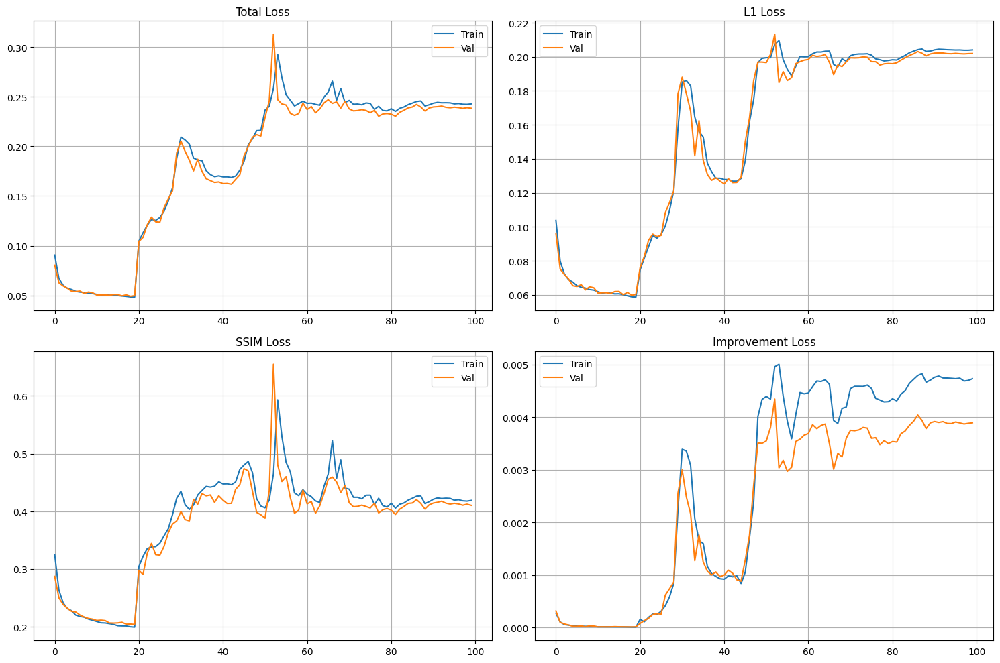

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(history['train_total'], label='Train')
axes[0, 0].plot(history['val_total'], label='Val')
axes[0, 0].set_title('Total Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(history['train_l1'], label='Train')
axes[0, 1].plot(history['val_l1'], label='Val')
axes[0, 1].set_title('L1 Loss')
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(history['train_ssim'], label='Train')
axes[1, 0].plot(history['val_ssim'], label='Val')
axes[1, 0].set_title('SSIM Loss')
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(history['train_improvement'], label='Train')
axes[1, 1].plot(history['val_improvement'], label='Val')
axes[1, 1].set_title('Improvement Loss')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(Path(CFG["save_dir"]) / 'training_history.png', dpi=150)
plt.show()

## Inference / Visualization

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load best model
checkpoint = torch.load(Path(CFG["save_dir"]) / 'best_model.pt', map_location=CFG["device"])
model.load_state_dict(checkpoint['model'])
model.eval()

print(f"✓ Loaded best model (epoch {checkpoint['epoch']+1}, val_loss: {checkpoint['val_loss']:.4f})")

✓ Loaded best model (epoch 19, val_loss: 0.0491)


In [48]:
@torch.no_grad()
def inference_comparison(model, dataset, indices, device, save_dir=None):
    """
    Compare CT, Draft, Refined, GT
    """
    model.eval()
    
    if save_dir:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
    
    results = []
    
    for idx in indices:
        batch = dataset[idx]
        
        # ⭐ Dataset의 samples에서 메타데이터 가져오기
        sample_info = dataset.samples[idx]
        patient = sample_info['patient']
        slice_name = sample_info['slice_name']
        group = sample_info['group']
        
        # Move to device
        selected_drafts = batch['selected_drafts'].unsqueeze(0).to(device)
        ct_center = batch['ct_center'].unsqueeze(0).to(device)
        mri_gt = batch['mri_gt'].unsqueeze(0).to(device)
        center_conf = batch['center_conf'].unsqueeze(0).to(device)
        
        # Get refined and draft_base
        refined, draft_base = model(selected_drafts, ct_center, center_conf)
        
        # To numpy [-1,1] → [0,1]
        ct_np = ((ct_center[0, 0].cpu().numpy() + 1) / 2)
        draft_np = ((draft_base[0, 0].cpu().numpy() + 1) / 2)
        refined_np = ((refined[0, 0].cpu().numpy() + 1) / 2)
        gt_np = ((mri_gt[0, 0].cpu().numpy() + 1) / 2)
        
        # Compute metrics
        draft_mae = np.abs(draft_np - gt_np).mean()
        refined_mae = np.abs(refined_np - gt_np).mean()
        improvement = ((draft_mae - refined_mae) / draft_mae) * 100
        
        results.append({
            'idx': idx,
            'patient': patient,
            'slice_name': slice_name,
            'group': group,
            'ct': ct_np,
            'draft': draft_np,
            'refined': refined_np,
            'gt': gt_np,
            'draft_mae': draft_mae,
            'refined_mae': refined_mae,
            'improvement': improvement,
            'confidence': center_conf.item()
        })
    
    return results

print("✓ inference_comparison function defined")

✓ inference_comparison function defined


In [51]:
def plot_comparison(results, figsize=(20, 5)):
    """Plot CT, Draft, Refined, GT comparison"""
    
    n_samples = len(results)
    fig, axes = plt.subplots(n_samples, 5, figsize=(figsize[0], figsize[1]*n_samples))
    
    if n_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, res in enumerate(results):
        # ⭐ 제목에 환자명/슬라이스 추가
        title_prefix = f"{res['patient']}/{res['slice_name']}"
        
        # CT
        axes[i, 0].imshow(res['ct'], cmap='gray', vmin=0, vmax=1)
        axes[i, 0].set_title(f"CT\n{title_prefix}")
        axes[i, 0].axis('off')
        
        # Draft
        axes[i, 1].imshow(res['draft'], cmap='gray', vmin=0, vmax=1)
        axes[i, 1].set_title(f"Draft\nMAE: {res['draft_mae']:.4f}")
        axes[i, 1].axis('off')
        
        # Refined
        axes[i, 2].imshow(res['refined'], cmap='gray', vmin=0, vmax=1)
        axes[i, 2].set_title(f"Refined\nMAE: {res['refined_mae']:.4f}")
        axes[i, 2].axis('off')
        
        # GT
        axes[i, 3].imshow(res['gt'], cmap='gray', vmin=0, vmax=1)
        axes[i, 3].set_title(f"GT\nConf: {res['confidence']:.3f}")
        axes[i, 3].axis('off')
        
        # Difference map
        diff_draft = np.abs(res['draft'] - res['gt'])
        diff_refined = np.abs(res['refined'] - res['gt'])
        diff_combined = np.stack([diff_draft, diff_refined, np.zeros_like(diff_draft)], axis=-1)
        
        axes[i, 4].imshow(diff_combined, vmin=0, vmax=0.3)
        axes[i, 4].set_title(f"Diff (R:Draft, G:Refined)\nImprove: {res['improvement']:.1f}%")
        axes[i, 4].axis('off')
    
    plt.tight_layout()
    return fig

print("✓ plot_comparison function defined")

✓ plot_comparison function defined


Visualizing 10 random samples from validation set...


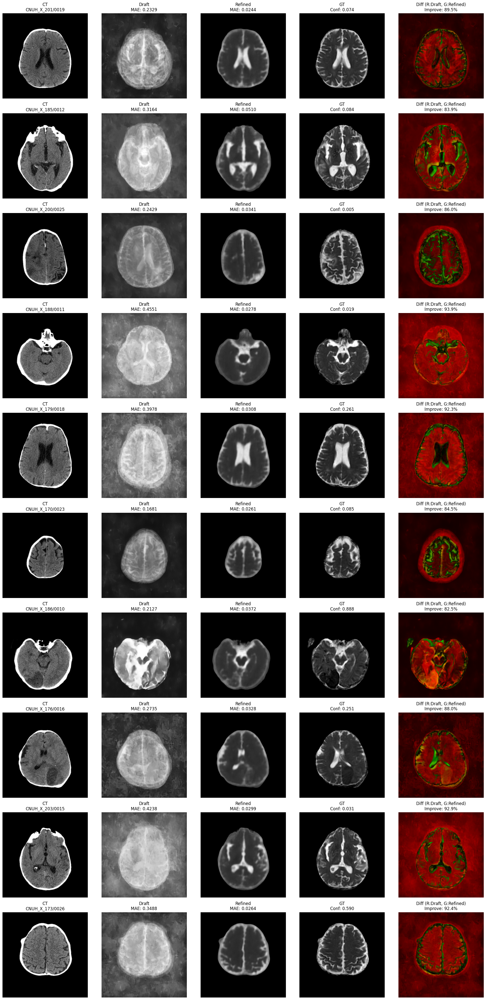


Inference Statistics (Validation)

Samples:
   1. CNUH_X_201/0019 (idx=521, improve=89.5%)
   2. CNUH_X_185/0012 (idx=284, improve=83.9%)
   3. CNUH_X_200/0025 (idx=513, improve=86.0%)
   4. CNUH_X_188/0011 (idx=331, improve=93.9%)
   5. CNUH_X_179/0018 (idx=210, improve=92.3%)
   6. CNUH_X_170/0023 (idx=90, improve=84.5%)
   7. CNUH_X_186/0010 (idx=299, improve=82.5%)
   8. CNUH_X_176/0016 (idx=181, improve=88.0%)
   9. CNUH_X_203/0015 (idx=545, improve=92.9%)
  10. CNUH_X_173/0026 (idx=137, improve=92.4%)

Draft MAE:   0.3072 ± 0.0919
Refined MAE: 0.0320 ± 0.0073
Improvement: 88.59% ± 3.99%


In [52]:
# Select random samples from validation set
np.random.seed(42)
n_vis = 10
vis_indices = np.random.choice(len(val_dataset), n_vis, replace=False)

print(f"Visualizing {n_vis} random samples from validation set...")

# Run inference
results = inference_comparison(
    model,
    val_dataset,
    vis_indices,
    CFG["device"],
    save_dir=Path(CFG["save_dir"]) / 'inference_results'
)

# Plot
fig = plot_comparison(results, figsize=(20, 4))
plt.savefig(Path(CFG["save_dir"]) / 'comparison_validation.png', dpi=150, bbox_inches='tight')
plt.show()

# Print statistics
print("\n" + "="*80)
print("Inference Statistics (Validation)")
print("="*80)

# ⭐ 샘플 정보 출력
print("\nSamples:")
for i, res in enumerate(results, 1):
    print(f"  {i:2d}. {res['patient']}/{res['slice_name']} (idx={res['idx']}, improve={res['improvement']:.1f}%)")

draft_maes = [r['draft_mae'] for r in results]
refined_maes = [r['refined_mae'] for r in results]
improvements = [r['improvement'] for r in results]

print(f"\nDraft MAE:   {np.mean(draft_maes):.4f} ± {np.std(draft_maes):.4f}")
print(f"Refined MAE: {np.mean(refined_maes):.4f} ± {np.std(refined_maes):.4f}")
print(f"Improvement: {np.mean(improvements):.2f}% ± {np.std(improvements):.2f}%")
print("="*80)

In [30]:
# Save individual images for each sample
output_dir = Path(CFG["save_dir"]) / 'individual_comparisons'
output_dir.mkdir(parents=True, exist_ok=True)

for res in results:
    idx = res['idx']
    
    # Create 4-panel image
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    axes[0].imshow(res['ct'], cmap='gray', vmin=0, vmax=1)
    axes[0].set_title('CT Input', fontsize=14)
    axes[0].axis('off')
    
    axes[1].imshow(res['draft'], cmap='gray', vmin=0, vmax=1)
    axes[1].set_title(f'Draft\nMAE: {res["draft_mae"]:.4f}', fontsize=14)
    axes[1].axis('off')
    
    axes[2].imshow(res['refined'], cmap='gray', vmin=0, vmax=1)
    axes[2].set_title(f'Refined\nMAE: {res["refined_mae"]:.4f}', fontsize=14)
    axes[2].axis('off')
    
    axes[3].imshow(res['gt'], cmap='gray', vmin=0, vmax=1)
    axes[3].set_title(f'Ground Truth\nImprove: {res["improvement"]:.1f}%', fontsize=14)
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.savefig(output_dir / f'sample_{idx:04d}.png', dpi=150, bbox_inches='tight')
    plt.close()

print(f"✓ Saved {len(results)} individual comparison images to: {output_dir}")

✓ Saved 10 individual comparison images to: ckpt_refiner/individual_comparisons



Evaluating on full validation set...


Evaluating: 100%|██████████| 37/37 [00:07<00:00,  5.03it/s]



Full Validation Set Results

Draft MAE:   0.5965 ± 0.2492
Refined MAE: 0.0598 ± 0.0175
Improvement: 87.03% ± 10.43%

Samples improved: 589 / 589


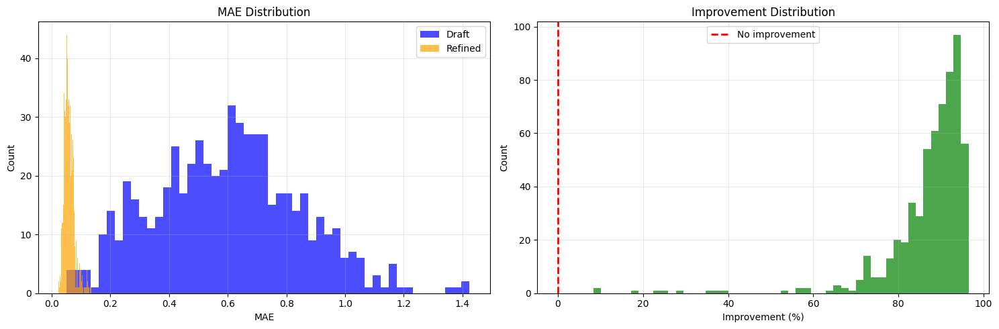

In [31]:
@torch.no_grad()
def evaluate_full_dataset(model, loader, device):
    """Evaluate on full dataset"""
    model.eval()
    
    draft_maes = []
    refined_maes = []
    improvements = []
    
    for batch in tqdm(loader, desc="Evaluating"):
        selected_drafts = batch['selected_drafts'].to(device)
        ct_center = batch['ct_center'].to(device)
        mri_gt = batch['mri_gt'].to(device)
        center_conf = batch['center_conf'].to(device)
        
        refined, draft_base = model(selected_drafts, ct_center, center_conf)
        
        # Compute MAE
        draft_mae = F.l1_loss(draft_base, mri_gt, reduction='none').mean(dim=(1,2,3))
        refined_mae = F.l1_loss(refined, mri_gt, reduction='none').mean(dim=(1,2,3))
        
        draft_maes.extend(draft_mae.cpu().numpy())
        refined_maes.extend(refined_mae.cpu().numpy())
        
        improve = ((draft_mae - refined_mae) / draft_mae * 100).cpu().numpy()
        improvements.extend(improve)
    
    return {
        'draft_mae': np.array(draft_maes),
        'refined_mae': np.array(refined_maes),
        'improvement': np.array(improvements)
    }

# Evaluate
print("\nEvaluating on full validation set...")
eval_results = evaluate_full_dataset(model, val_loader, CFG["device"])

print("\n" + "="*80)
print("Full Validation Set Results")
print("="*80)
print(f"\nDraft MAE:   {eval_results['draft_mae'].mean():.4f} ± {eval_results['draft_mae'].std():.4f}")
print(f"Refined MAE: {eval_results['refined_mae'].mean():.4f} ± {eval_results['refined_mae'].std():.4f}")
print(f"Improvement: {eval_results['improvement'].mean():.2f}% ± {eval_results['improvement'].std():.2f}%")
print(f"\nSamples improved: {(eval_results['improvement'] > 0).sum()} / {len(eval_results['improvement'])}")
print("="*80)

# Plot histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(eval_results['draft_mae'], bins=50, alpha=0.7, label='Draft', color='blue')
axes[0].hist(eval_results['refined_mae'], bins=50, alpha=0.7, label='Refined', color='orange')
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Count')
axes[0].set_title('MAE Distribution')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(eval_results['improvement'], bins=50, color='green', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='No improvement')
axes[1].set_xlabel('Improvement (%)')
axes[1].set_ylabel('Count')
axes[1].set_title('Improvement Distribution')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["save_dir"]) / 'evaluation_histograms.png', dpi=150)
plt.show()


Best Improvements
1. Sample 222: 96.45% improvement
   Draft MAE: 1.4228 → Refined MAE: 0.0506
2. Sample 224: 96.39% improvement
   Draft MAE: 1.4235 → Refined MAE: 0.0514
3. Sample 257: 96.07% improvement
   Draft MAE: 0.8632 → Refined MAE: 0.0339
4. Sample 458: 95.99% improvement
   Draft MAE: 0.8922 → Refined MAE: 0.0357
5. Sample 471: 95.95% improvement
   Draft MAE: 0.7507 → Refined MAE: 0.0304

Worst Cases (Degradation)
1. Sample 443: 8.32% change
   Draft MAE: 0.0496 → Refined MAE: 0.0455
2. Sample 295: 8.75% change
   Draft MAE: 0.1128 → Refined MAE: 0.1029
3. Sample 281: 17.51% change
   Draft MAE: 0.1276 → Refined MAE: 0.1053
4. Sample 315: 22.57% change
   Draft MAE: 0.0581 → Refined MAE: 0.0450
5. Sample 145: 24.77% change
   Draft MAE: 0.0854 → Refined MAE: 0.0642

Visualizing best improvements...


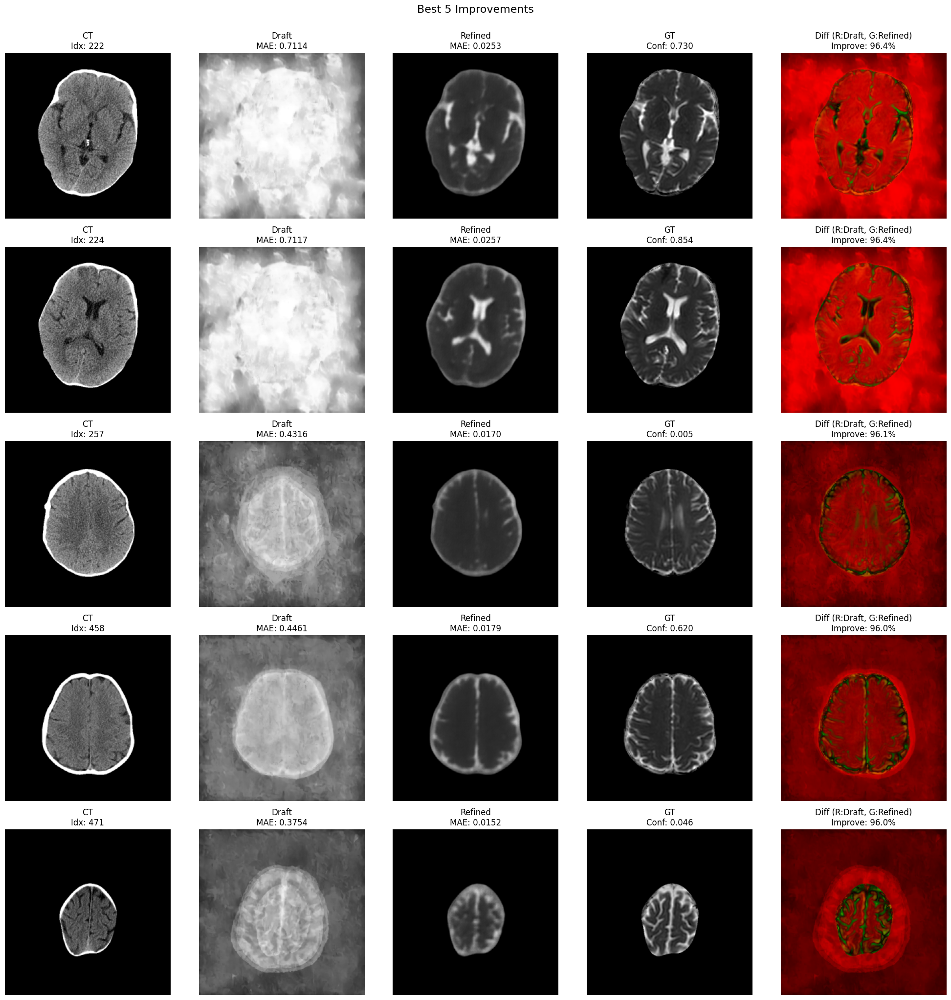


Visualizing worst cases...


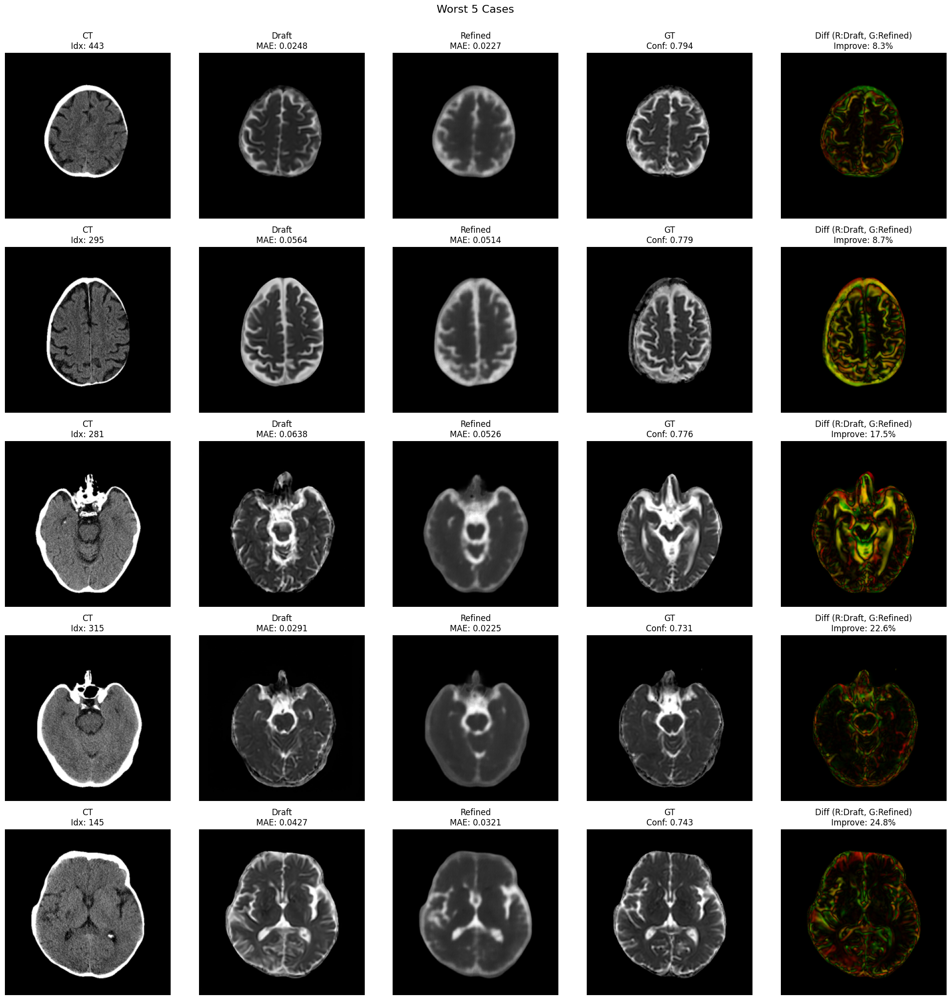

In [32]:
# Find best and worst improvements
sorted_indices = np.argsort(eval_results['improvement'])

worst_5 = sorted_indices[:5]
best_5 = sorted_indices[-5:][::-1]

print("\n" + "="*80)
print("Best Improvements")
print("="*80)
for rank, idx in enumerate(best_5, 1):
    print(f"{rank}. Sample {idx}: {eval_results['improvement'][idx]:.2f}% improvement")
    print(f"   Draft MAE: {eval_results['draft_mae'][idx]:.4f} → Refined MAE: {eval_results['refined_mae'][idx]:.4f}")

print("\n" + "="*80)
print("Worst Cases (Degradation)")
print("="*80)
for rank, idx in enumerate(worst_5, 1):
    print(f"{rank}. Sample {idx}: {eval_results['improvement'][idx]:.2f}% change")
    print(f"   Draft MAE: {eval_results['draft_mae'][idx]:.4f} → Refined MAE: {eval_results['refined_mae'][idx]:.4f}")
print("="*80)

# Visualize best cases
print("\nVisualizing best improvements...")
best_results = inference_comparison(model, val_dataset, best_5.tolist(), CFG["device"])
fig = plot_comparison(best_results, figsize=(20, 4))
plt.suptitle('Best 5 Improvements', fontsize=16, y=1.02)
plt.savefig(Path(CFG["save_dir"]) / 'best_improvements.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualize worst cases
print("\nVisualizing worst cases...")
worst_results = inference_comparison(model, val_dataset, worst_5.tolist(), CFG["device"])
fig = plot_comparison(worst_results, figsize=(20, 4))
plt.suptitle('Worst 5 Cases', fontsize=16, y=1.02)
plt.savefig(Path(CFG["save_dir"]) / 'worst_cases.png', dpi=150, bbox_inches='tight')
plt.show()

In [53]:
@torch.no_grad()
def detailed_inference(model, dataset, idx, device):
    """
    Show complete context window and refinement process
    
    Returns:
        - Context window (±5 slices)
        - Selected top 5 drafts
        - CT input
        - Draft base (adaptive selection)
        - Refined output
        - GT
    """
    model.eval()
    
    batch = dataset[idx]
    sample_info = dataset.samples[idx]
    
    # Get metadata
    patient = sample_info['patient']
    slice_name = sample_info['slice_name']
    center_idx = sample_info['slice_idx']
    total_slices = sample_info['total_slices']
    all_slices = sample_info['all_slices']
    
    # Define context window (same logic as dataset)
    if center_idx < 5:
        start, end = 0, min(center_idx + 6, total_slices)
    elif center_idx >= total_slices - 5:
        start, end = max(center_idx - 5, 0), total_slices
    else:
        start, end = center_idx - 5, center_idx + 6
    
    # Load all context drafts with confidences
    context_drafts = []
    context_confs = []
    context_slice_names = []
    
    for i in range(start, end):
        slice_name_i = all_slices[i]
        
        # Load draft
        draft_path = dataset.draft_dir / sample_info['group'] / patient / f"{slice_name_i}.png"
        draft = load_image(draft_path, dataset.img_size)
        context_drafts.append(draft)
        
        # Get confidence
        key = f"{sample_info['group']}/{patient}/{slice_name_i}"
        conf = dataset.confidences.get(key, 0.5)
        context_confs.append(conf)
        context_slice_names.append(slice_name_i)
    
    # Get top 5 indices
    context_confs_arr = np.array(context_confs)
    if len(context_confs_arr) >= 5:
        top_indices = np.argsort(context_confs_arr)[-5:][::-1]
    else:
        top_indices = np.arange(len(context_confs_arr))
    
    # Move to device
    selected_drafts = batch['selected_drafts'].unsqueeze(0).to(device)
    ct_center = batch['ct_center'].unsqueeze(0).to(device)
    mri_gt = batch['mri_gt'].unsqueeze(0).to(device)
    center_conf = batch['center_conf'].unsqueeze(0).to(device)
    
    # Get refined and draft_base
    refined, draft_base = model(selected_drafts, ct_center, center_conf)
    
    # Convert to numpy [0, 1]
    context_drafts_np = [d for d in context_drafts]
    ct_np = ((ct_center[0, 0].cpu().numpy() + 1) / 2)
    draft_base_np = ((draft_base[0, 0].cpu().numpy() + 1) / 2)
    refined_np = ((refined[0, 0].cpu().numpy() + 1) / 2)
    gt_np = ((mri_gt[0, 0].cpu().numpy() + 1) / 2)
    
    # Metrics
    draft_mae = np.abs(draft_base_np - gt_np).mean()
    refined_mae = np.abs(refined_np - gt_np).mean()
    improvement = ((draft_mae - refined_mae) / draft_mae) * 100
    
    return {
        'patient': patient,
        'center_slice': slice_name,
        'center_idx': center_idx,
        'context_window': (start, end),
        'context_drafts': context_drafts_np,
        'context_confs': context_confs,
        'context_slice_names': context_slice_names,
        'top_indices': top_indices,
        'center_conf': center_conf.item(),
        'ct': ct_np,
        'draft_base': draft_base_np,
        'refined': refined_np,
        'gt': gt_np,
        'draft_mae': draft_mae,
        'refined_mae': refined_mae,
        'improvement': improvement,
    }

print("✓ detailed_inference function defined")

✓ detailed_inference function defined


In [54]:
def plot_detailed_comparison(result, figsize=(20, 15)):
    """
    Detailed visualization showing:
    Row 1: All context window drafts with confidences
    Row 2: Top 5 selected drafts
    Row 3: CT → Draft Base → Refined → GT
    """
    
    n_context = len(result['context_drafts'])
    n_cols = max(n_context, 5)
    
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(4, n_cols, hspace=0.3, wspace=0.2)
    
    # Title
    fig.suptitle(
        f"Patient: {result['patient']} | Center Slice: {result['center_slice']} "
        f"(idx={result['center_idx']})\n"
        f"Context Window: {result['context_window']} | Center Confidence: {result['center_conf']:.3f}",
        fontsize=14, fontweight='bold'
    )
    
    # Row 1: All context drafts
    for i, (draft, conf, slice_name) in enumerate(zip(
            result['context_drafts'], 
            result['context_confs'],
            result['context_slice_names'])):
        
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(draft, cmap='gray', vmin=0, vmax=1)
        
        # Highlight if selected in top 5
        is_selected = i in result['top_indices']
        color = 'red' if is_selected else 'blue'
        linewidth = 3 if is_selected else 1
        
        # Highlight center slice
        is_center = slice_name == result['center_slice']
        if is_center:
            color = 'green'
            linewidth = 4
        
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(linewidth)
        
        title = f"{slice_name}\nConf: {conf:.3f}"
        if is_center:
            title += "\n[CENTER]"
        if is_selected:
            title += "\n[TOP5]"
        
        ax.set_title(title, fontsize=9, color=color, fontweight='bold' if (is_selected or is_center) else 'normal')
        ax.axis('off')
    
    # Fill empty slots in row 1
    for i in range(n_context, n_cols):
        ax = fig.add_subplot(gs[0, i])
        ax.axis('off')
    
    # Row 2: Top 5 selected (with ranking)
    top_5_drafts = [result['context_drafts'][i] for i in result['top_indices']]
    top_5_confs = [result['context_confs'][i] for i in result['top_indices']]
    top_5_names = [result['context_slice_names'][i] for i in result['top_indices']]
    
    # Pad to 5
    while len(top_5_drafts) < 5:
        top_5_drafts.append(np.zeros_like(top_5_drafts[0]))
        top_5_confs.append(0.0)
        top_5_names.append("PADDED")
    
    start_col = (n_cols - 5) // 2
    for i in range(5):
        ax = fig.add_subplot(gs[1, start_col + i])
        ax.imshow(top_5_drafts[i], cmap='gray', vmin=0, vmax=1)
        
        is_padded = top_5_names[i] == "PADDED"
        if not is_padded:
            ax.set_title(f"Rank {i+1}\n{top_5_names[i]}\nConf: {top_5_confs[i]:.3f}", fontsize=10)
            for spine in ax.spines.values():
                spine.set_edgecolor('red')
                spine.set_linewidth(2)
        else:
            ax.set_title("Padded", fontsize=10, color='gray')
        
        ax.axis('off')
    
    # Row 2 title
    ax_title = fig.add_subplot(gs[1, :start_col])
    ax_title.text(0.5, 0.5, "Top 5 Selected\n(Input to Refiner)", 
                  ha='center', va='center', fontsize=12, fontweight='bold')
    ax_title.axis('off')
    
    # Row 3: Refinement process
    start_col = (n_cols - 5) // 2
    
    # CT Input
    ax = fig.add_subplot(gs[2, start_col])
    ax.imshow(result['ct'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("CT Input", fontsize=11, fontweight='bold')
    ax.axis('off')
    
    # Draft Base (adaptive selection)
    ax = fig.add_subplot(gs[2, start_col + 1])
    ax.imshow(result['draft_base'], cmap='gray', vmin=0, vmax=1)
    strategy = "Use Center" if result['center_conf'] > 0.7 else "Use Neighbors Avg"
    ax.set_title(f"Draft Base\n({strategy})\nMAE: {result['draft_mae']:.4f}", fontsize=11)
    ax.axis('off')
    
    # Refined
    ax = fig.add_subplot(gs[2, start_col + 2])
    ax.imshow(result['refined'], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Refined Output\nMAE: {result['refined_mae']:.4f}", fontsize=11, fontweight='bold', color='green')
    for spine in ax.spines.values():
        spine.set_edgecolor('green')
        spine.set_linewidth(3)
    ax.axis('off')
    
    # GT
    ax = fig.add_subplot(gs[2, start_col + 3])
    ax.imshow(result['gt'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("Ground Truth", fontsize=11, fontweight='bold')
    ax.axis('off')
    
    # Improvement
    ax = fig.add_subplot(gs[2, start_col + 4])
    ax.text(0.5, 0.5, f"Improvement\n{result['improvement']:.1f}%", 
            ha='center', va='center', fontsize=14, fontweight='bold',
            color='green' if result['improvement'] > 0 else 'red')
    ax.axis('off')
    
    # Row 4: Difference maps
    start_col = (n_cols - 4) // 2
    
    # Draft error
    ax = fig.add_subplot(gs[3, start_col])
    draft_error = np.abs(result['draft_base'] - result['gt'])
    im = ax.imshow(draft_error, cmap='hot', vmin=0, vmax=0.3)
    ax.set_title(f"Draft Error\n(avg: {draft_error.mean():.4f})", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
    
    # Refined error
    ax = fig.add_subplot(gs[3, start_col + 1])
    refined_error = np.abs(result['refined'] - result['gt'])
    im = ax.imshow(refined_error, cmap='hot', vmin=0, vmax=0.3)
    ax.set_title(f"Refined Error\n(avg: {refined_error.mean():.4f})", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
    
    # Error reduction
    ax = fig.add_subplot(gs[3, start_col + 2])
    error_reduction = draft_error - refined_error
    im = ax.imshow(error_reduction, cmap='RdYlGn', vmin=-0.1, vmax=0.1)
    ax.set_title(f"Error Reduction\n(Green=Better)", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
    
    # Combined difference
    ax = fig.add_subplot(gs[3, start_col + 3])
    diff_combined = np.stack([draft_error, refined_error, np.zeros_like(draft_error)], axis=-1)
    ax.imshow(diff_combined, vmin=0, vmax=0.3)
    ax.set_title("Combined\n(R:Draft, G:Refined)", fontsize=10)
    ax.axis('off')
    
    return fig

print("✓ plot_detailed_comparison function defined")

✓ plot_detailed_comparison function defined


Detailed analysis for sample 100...


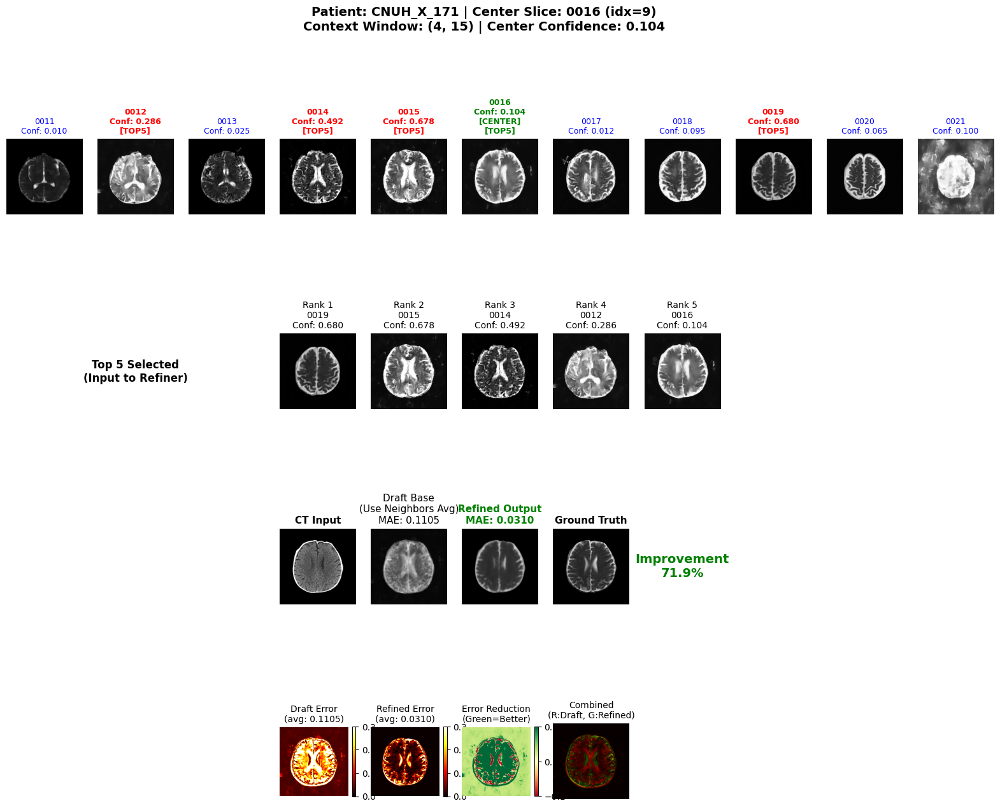


Patient: CNUH_X_171
Center Slice: 0016 (idx=9)
Context Window: (4, 15)
Center Confidence: 0.104

Top 5 Selected Slices:
  1. 0019 (conf=0.680)
  2. 0015 (conf=0.678)
  3. 0014 (conf=0.492)
  4. 0012 (conf=0.286)
  5. 0016 (conf=0.104)

Draft MAE: 0.1105
Refined MAE: 0.0310
Improvement: 71.9%


In [56]:
# 특정 샘플 상세 분석
sample_idx = 100  # 원하는 인덱스

print(f"Detailed analysis for sample {sample_idx}...")
detail_result = detailed_inference(model, val_dataset, sample_idx, CFG["device"])

# 시각화
fig = plot_detailed_comparison(detail_result, figsize=(20, 15))
plt.savefig(Path(CFG["save_dir"]) / f'detailed_sample_{sample_idx}.png', 
            dpi=150, bbox_inches='tight')
plt.show()

# 정보 출력
print(f"\nPatient: {detail_result['patient']}")
print(f"Center Slice: {detail_result['center_slice']} (idx={detail_result['center_idx']})")
print(f"Context Window: {detail_result['context_window']}")
print(f"Center Confidence: {detail_result['center_conf']:.3f}")
print(f"\nTop 5 Selected Slices:")
for rank, idx in enumerate(detail_result['top_indices'], 1):
    slice_name = detail_result['context_slice_names'][idx]
    conf = detail_result['context_confs'][idx]
    print(f"  {rank}. {slice_name} (conf={conf:.3f})")
print(f"\nDraft MAE: {detail_result['draft_mae']:.4f}")
print(f"Refined MAE: {detail_result['refined_mae']:.4f}")
print(f"Improvement: {detail_result['improvement']:.1f}%")

In [57]:
@torch.no_grad()
def inference_eval_folder(unet, cond_enc, vae, model_refiner, sched_dict, 
                          eval_root, output_dir, ddim_steps=200, device="cuda"):
    """
    Inference on eval folder (no GT available)
    
    Shows: CT → Draft (LDM) → Refined (Refiner)
    """
    
    print("\n" + "="*80)
    print("Eval Folder Inference")
    print("="*80)
    
    eval_root = Path(eval_root)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Collect eval CT files
    eval_patients = []
    for patient_dir in sorted(eval_root.glob("*")):
        if not patient_dir.is_dir():
            continue
        
        ct_dir = patient_dir / 'ct_axial'
        if not ct_dir.exists():
            continue
        
        ct_files = sorted(ct_dir.glob('*.png'))
        if len(ct_files) == 0:
            continue
        
        eval_patients.append({
            'patient': patient_dir.name,
            'ct_dir': ct_dir,
            'ct_files': ct_files
        })
    
    print(f"Found {len(eval_patients)} patients in eval folder")
    
    # Set models to eval mode
    unet.eval()
    cond_enc.eval()
    vae.eval()
    model_refiner.eval()
    
    # Process each patient
    all_results = []
    
    for patient_info in tqdm(eval_patients, desc="Processing patients"):
        patient = patient_info['patient']
        ct_files = patient_info['ct_files']
        
        print(f"\nProcessing {patient}: {len(ct_files)} slices")
        
        # Generate drafts for all slices
        drafts = []
        ct_arrays = []
        slice_names = []
        
        for ct_file in tqdm(ct_files, desc=f"  Generating drafts", leave=False):
            # Load CT
            ct = load_image(ct_file)
            ct_tensor = torch.from_numpy(ct).unsqueeze(0).unsqueeze(0).to(device)
            ct_tensor = ct_tensor * 2 - 1
            
            # Generate draft
            draft = sample_ddim_latent(
                unet, cond_enc, vae, ct_tensor, sched_dict,
                ddim_steps=ddim_steps, eta=0.0, device=device
            )
            
            drafts.append(draft)
            ct_arrays.append(ct)
            slice_names.append(ct_file.stem)
        
        # Calculate confidences (simple variance-based)
        confidences = []
        for i in tqdm(range(len(drafts)), desc="  Computing confidences", leave=False):
            # Use draft variance as proxy for confidence
            draft_var = drafts[i].var().item()
            conf = np.exp(-draft_var * 10.0)
            confidences.append(conf)
        
        # Refine each slice using context window
        refined_results = []
        
        for center_idx in tqdm(range(len(drafts)), desc="  Refining", leave=False):
            # Context window
            if center_idx < 5:
                start, end = 0, min(center_idx + 6, len(drafts))
            elif center_idx >= len(drafts) - 5:
                start, end = max(center_idx - 5, 0), len(drafts)
            else:
                start, end = center_idx - 5, center_idx + 6
            
            # Get context drafts
            context_drafts_list = []
            context_confs = []
            
            for i in range(start, end):
                # Convert draft to numpy [0, 1]
                draft_np = ((drafts[i][0, 0].cpu().numpy() + 1) / 2)
                context_drafts_list.append(draft_np)
                context_confs.append(confidences[i])
            
            # Select top 5
            context_confs_arr = np.array(context_confs)
            if len(context_confs_arr) >= 5:
                top_indices = np.argsort(context_confs_arr)[-5:][::-1]
            else:
                top_indices = np.arange(len(context_confs_arr))
            
            selected_drafts_list = [context_drafts_list[i] for i in top_indices]
            selected_confs = context_confs_arr[top_indices]
            
            # Pad to 5
            while len(selected_drafts_list) < 5:
                selected_drafts_list.append(np.zeros_like(selected_drafts_list[0]))
                selected_confs = np.append(selected_confs, 0.0)
            
            # To tensor
            selected_drafts_t = torch.stack([
                torch.from_numpy(d) for d in selected_drafts_list
            ]).float().unsqueeze(0).to(device)
            selected_drafts_t = selected_drafts_t * 2 - 1
            
            # CT center
            ct_center = torch.from_numpy(ct_arrays[center_idx]).unsqueeze(0).unsqueeze(0).to(device)
            ct_center = ct_center * 2 - 1
            
            # Center confidence
            center_conf = torch.tensor(confidences[center_idx]).unsqueeze(0).float().to(device)
            
            # Refine
            refined, draft_base = model_refiner(selected_drafts_t, ct_center, center_conf)
            
            # Save result
            refined_results.append({
                'slice_name': slice_names[center_idx],
                'center_idx': center_idx,
                'ct': ct_arrays[center_idx],
                'draft': (drafts[center_idx][0, 0].cpu().numpy() + 1) / 2,
                'draft_base': (draft_base[0, 0].cpu().numpy() + 1) / 2,
                'refined': (refined[0, 0].cpu().numpy() + 1) / 2,
                'center_conf': confidences[center_idx],
                'context_window': (start, end),
                'top_indices': top_indices,
            })
        
        # Save patient results
        patient_dir = output_dir / patient
        patient_dir.mkdir(parents=True, exist_ok=True)
        
        # Save individual images
        for res in refined_results:
            # Draft
            draft_img = Image.fromarray((res['draft'] * 255).astype(np.uint8), 'L')
            draft_img.save(patient_dir / f"{res['slice_name']}_draft.png")
            
            # Refined
            refined_img = Image.fromarray((res['refined'] * 255).astype(np.uint8), 'L')
            refined_img.save(patient_dir / f"{res['slice_name']}_refined.png")
        
        all_results.append({
            'patient': patient,
            'results': refined_results
        })
        
        print(f"  ✓ Saved {len(refined_results)} results to {patient_dir}")
    
    print("\n" + "="*80)
    print(f"✓ Eval inference complete!")
    print(f"  Total patients: {len(all_results)}")
    print(f"  Output directory: {output_dir}")
    print("="*80)
    
    return all_results

print("✓ inference_eval_folder function defined")

✓ inference_eval_folder function defined


In [63]:
def plot_eval_comparison(patient_results, n_samples=5, figsize=(20, 4)):
    """
    Plot CT → Draft → Refined for eval samples
    """
    
    results = patient_results['results']
    patient = patient_results['patient']
    
    # Sample evenly
    indices = np.linspace(0, len(results)-1, n_samples, dtype=int)
    
    fig, axes = plt.subplots(n_samples, 4, figsize=(figsize[0], figsize[1]*n_samples))
    
    if n_samples == 1:
        axes = axes.reshape(1, -1)
    
    fig.suptitle(f"Patient: {patient}", fontsize=16, fontweight='bold')
    
    for i, idx in enumerate(indices):
        res = results[idx]
        
        # CT
        axes[i, 0].imshow(res['ct'], cmap='gray', vmin=0, vmax=1)
        axes[i, 0].set_title(f"CT\n{res['slice_name']}")
        axes[i, 0].axis('off')
        
        # Draft
        axes[i, 1].imshow(res['draft'], cmap='gray', vmin=0, vmax=1)
        axes[i, 1].set_title(f"Draft (LDM)\nConf: {res['center_conf']:.3f}")
        axes[i, 1].axis('off')
        
        # Draft Base
        axes[i, 2].imshow(res['draft_base'], cmap='gray', vmin=0, vmax=1)
        strategy = "Center" if res['center_conf'] > 0.7 else "Avg"
        axes[i, 2].set_title(f"Draft Base\n({strategy})")
        axes[i, 2].axis('off')
        
        # Refined
        axes[i, 3].imshow(res['refined'], cmap='gray', vmin=0, vmax=1)
        axes[i, 3].set_title("Refined (Stage 2)")
        axes[i, 3].axis('off')
        for spine in axes[i, 3].spines.values():
            spine.set_edgecolor('green')
            spine.set_linewidth(3)
    
    plt.tight_layout()
    return fig

print("✓ plot_eval_comparison function defined")

✓ plot_eval_comparison function defined


In [59]:
# Run eval inference
eval_results = inference_eval_folder(
    unet, cond_enc, vae, model,
    sched_dict,
    eval_root=Path(CFG["data_root"]) / "eval",
    output_dir=Path(CFG["save_dir"]) / "eval_results",
    ddim_steps=CFG["ddim_steps"],
    device=CFG["device"]
)

print(f"\n✓ Processed {len(eval_results)} eval patients")


Eval Folder Inference
Found 4 patients in eval folder


Processing patients:   0%|          | 0/4 [00:00<?, ?it/s]


Processing CNUH_001: 15 slices



  Generating drafts: 100%|██████████| 15/15 [00:29<00:00,  1.99s/it]
                                                                    
  Computing confidences:   0%|          | 0/15 [00:00<?, ?it/s]
                                                               
Processing patients:  25%|██▌       | 1/4 [00:30<01:30, 30.09s/it]

  ✓ Saved 15 results to ckpt_refiner/eval_results/CNUH_001

Processing CNUH_002: 16 slices


...

  ✓ Saved 16 results to ckpt_refiner/eval_results/CNUH_002

Processing CNUH_X_001: 14 slices



  Generating drafts: 100%|██████████| 14/14 [00:27<00:00,  1.98s/it]
                                                                    
  Computing confidences:   0%|          | 0/14 [00:00<?, ?it/s]
                                                               
Processing patients:  75%|███████▌  | 3/4 [01:30<00:29, 29.81s/it]

  ✓ Saved 14 results to ckpt_refiner/eval_results/CNUH_X_001

Processing CNUH_X_003: 17 slices



  Generating drafts: 100%|██████████| 17/17 [00:33<00:00,  1.98s/it]
                                                                    
  Computing confidences:   0%|          | 0/17 [00:00<?, ?it/s]
                                                               
Processing patients: 100%|██████████| 4/4 [02:04<00:00, 31.08s/it]

  ✓ Saved 17 results to ckpt_refiner/eval_results/CNUH_X_003

✓ Eval inference complete!
  Total patients: 4
  Output directory: ckpt_refiner/eval_results

✓ Processed 4 eval patients


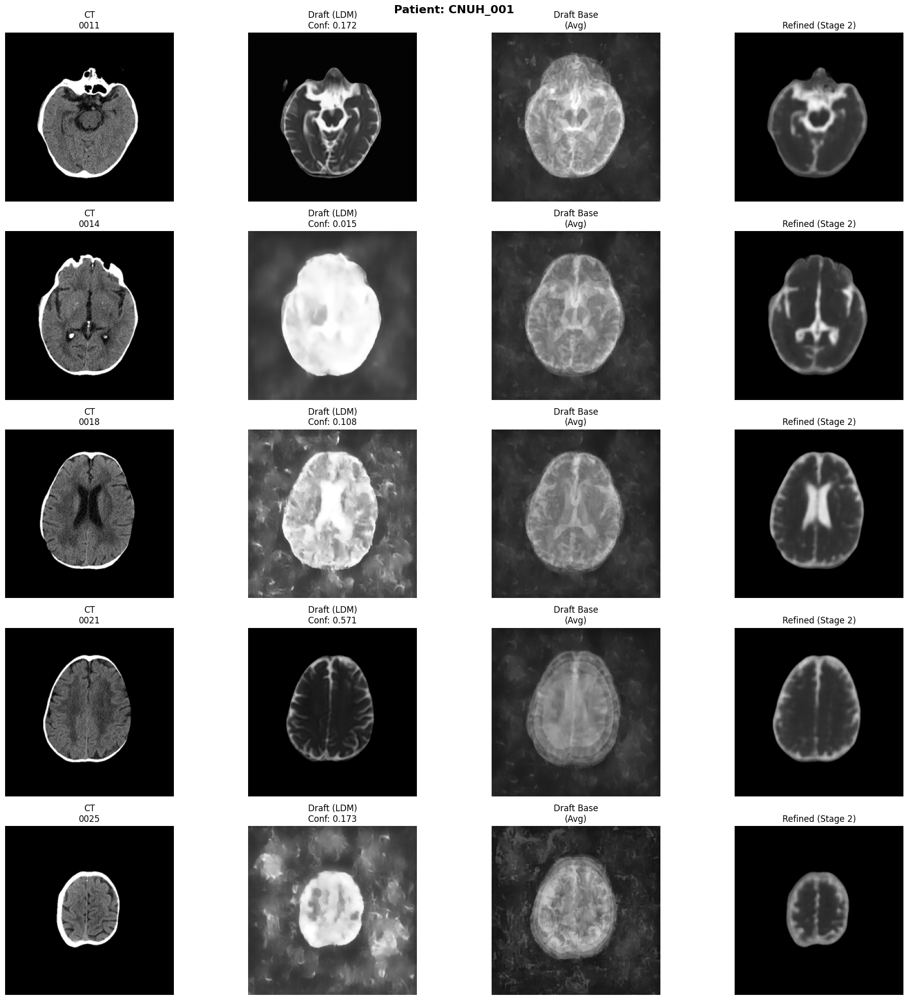

✓ Visualized patient: CNUH_001


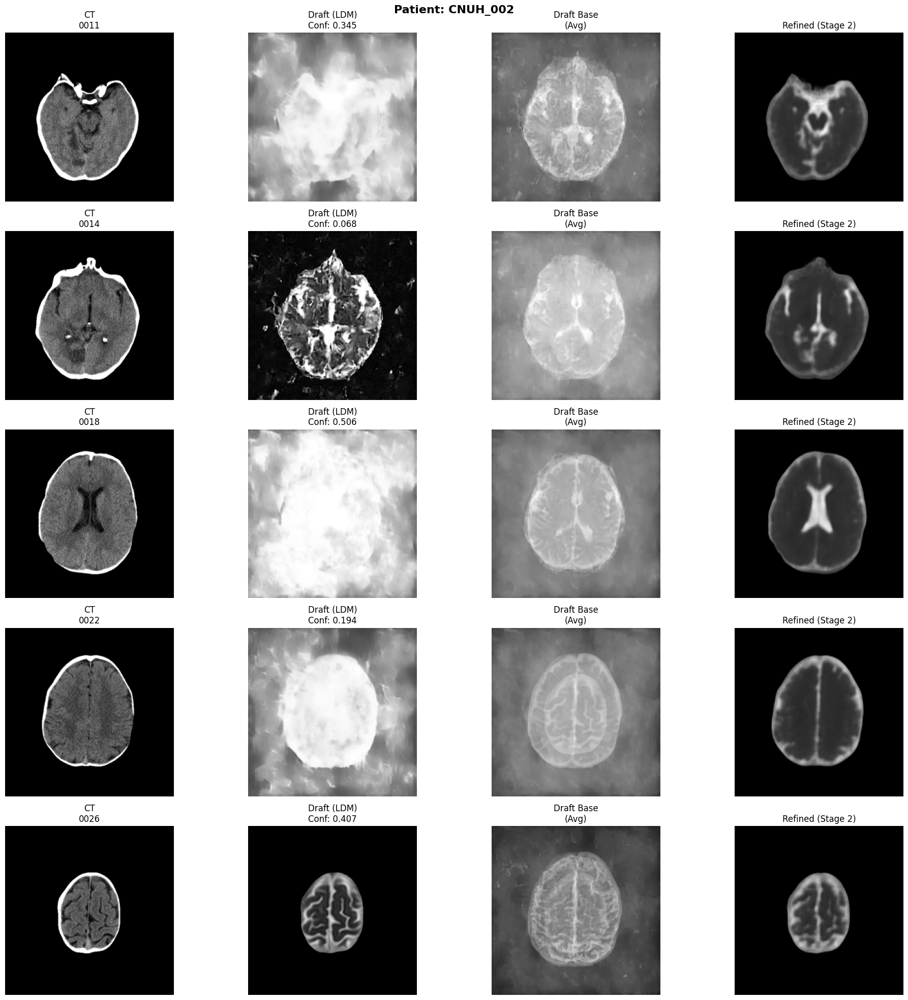

✓ Visualized patient: CNUH_002


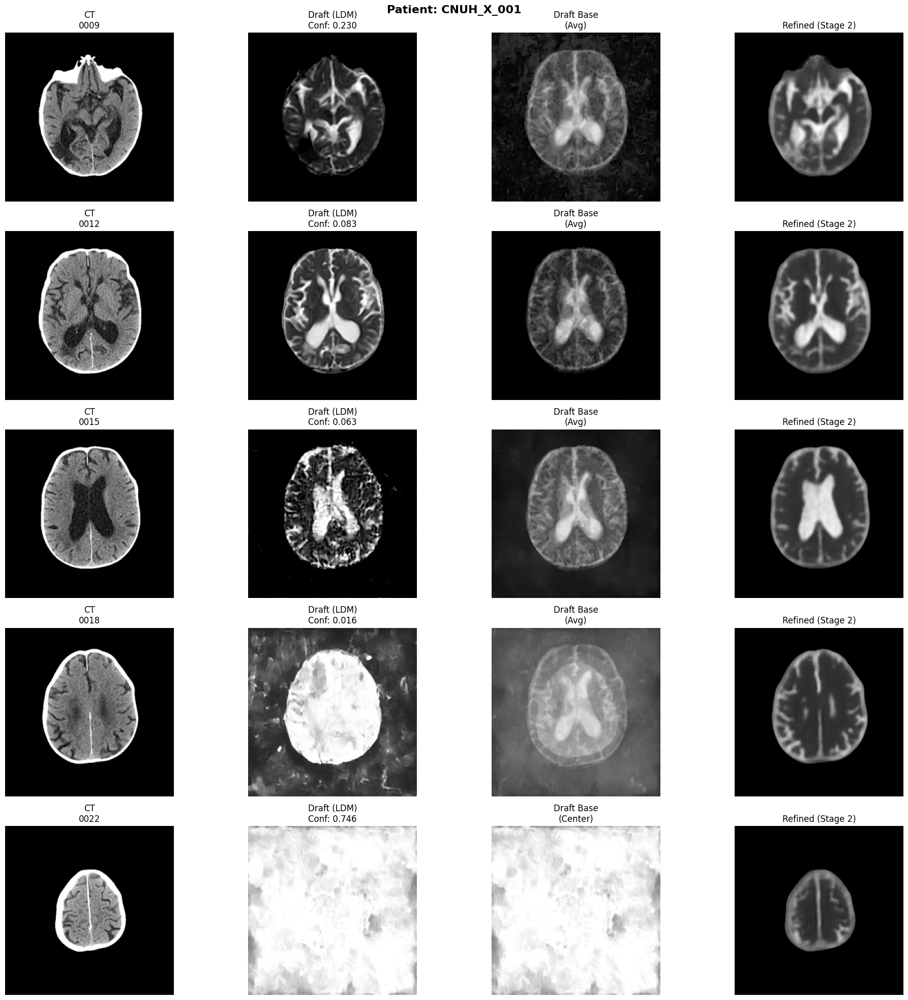

✓ Visualized patient: CNUH_X_001


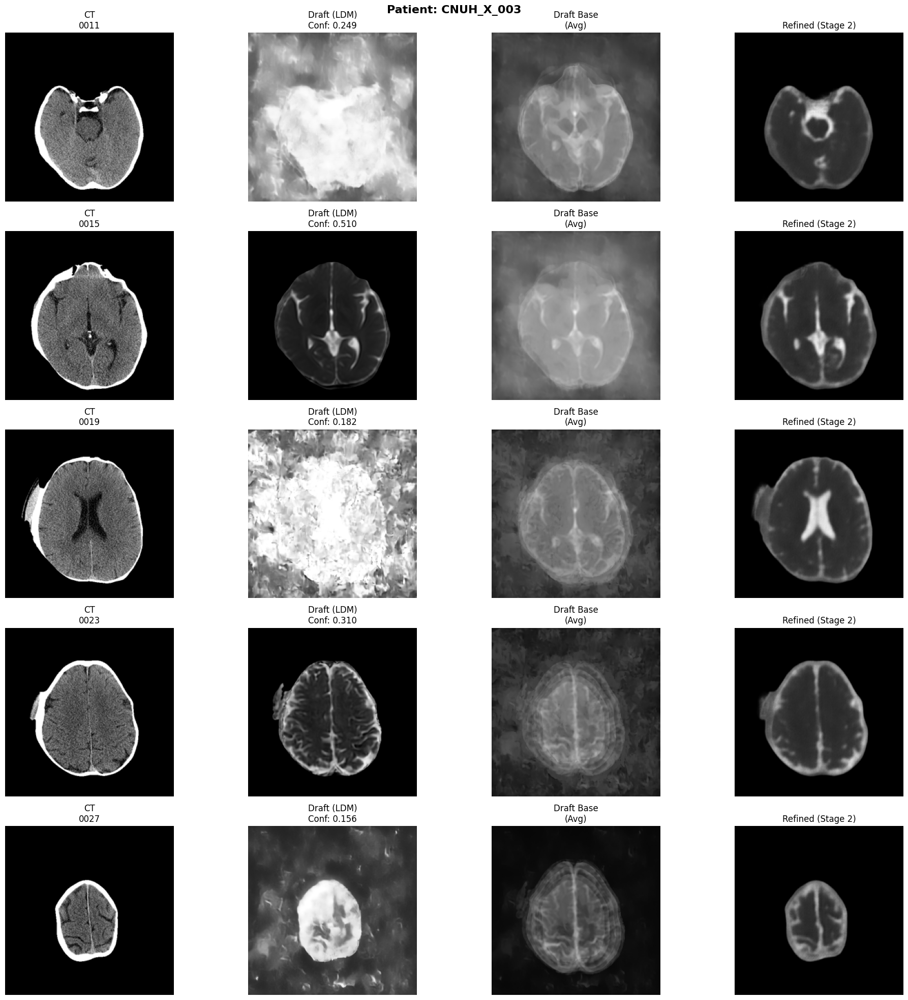

✓ Visualized patient: CNUH_X_003


In [64]:
# Visualize each patient
for patient_result in eval_results:
    patient = patient_result['patient']
    
    # Plot comparison
    fig = plot_eval_comparison(patient_result, n_samples=5, figsize=(20, 4))
    plt.savefig(
        Path(CFG["save_dir"]) / "eval_results" / f"{patient}_comparison.png",
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    
    print(f"✓ Visualized patient: {patient}")

In [66]:
def plot_detailed_eval(patient_results, slice_idx, figsize=(22, 16)):
    """
    Detailed visualization for eval sample (no GT)
    
    Shows:
    - Row 1: All context window drafts with confidences
    - Row 2: Top 5 selected drafts (input to refiner)
    - Row 3: CT → Draft Base (adaptive) → Refined
    - Row 4: Comparison (Draft vs Refined)
    """
    
    results = patient_results['results']
    patient = patient_results['patient']
    res = results[slice_idx]
    
    # Get context window info
    start, end = res['context_window']
    context_size = end - start
    
    # Load all context drafts
    context_drafts = []
    context_confs = []
    context_names = []
    
    for i in range(start, end):
        if i < len(results):
            context_drafts.append(results[i]['draft'])
            context_confs.append(results[i]['center_conf'])
            context_names.append(results[i]['slice_name'])
    
    n_cols = max(context_size, 5)
    
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(5, n_cols, hspace=0.4, wspace=0.2)
    
    # Title
    fig.suptitle(
        f"Patient: {patient} | Center Slice: {res['slice_name']} (idx={res['center_idx']})\n"
        f"Context Window: [{start}, {end}) | Center Confidence: {res['center_conf']:.3f}",
        fontsize=16, fontweight='bold', y=0.98
    )
    
    # ============================================
    # Row 1: All Context Window Drafts
    # ============================================
    for i in range(len(context_drafts)):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(context_drafts[i], cmap='gray', vmin=0, vmax=1)
        
        # Check if this is center
        is_center = (start + i) == res['center_idx']
        
        # Check if this is in top 5
        is_selected = i in res['top_indices']
        
        # Border color
        if is_center:
            color = 'lime'
            linewidth = 5
        elif is_selected:
            color = 'red'
            linewidth = 3
        else:
            color = 'blue'
            linewidth = 1
        
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(linewidth)
        
        # Title
        title = f"Slice {start+i}\n{context_names[i][:8]}...\nConf: {context_confs[i]:.3f}"
        if is_center:
            title = f"★ CENTER ★\n{title}"
        if is_selected:
            title += "\n[TOP5]"
        
        ax.set_title(title, fontsize=9, 
                    color=color, 
                    fontweight='bold' if (is_center or is_selected) else 'normal')
        ax.axis('off')
    
    # Fill empty slots
    for i in range(len(context_drafts), n_cols):
        ax = fig.add_subplot(gs[0, i])
        ax.axis('off')
    
    # Row 1 label
    ax_label = fig.add_subplot(gs[0, :])
    ax_label.text(-0.02, 0.5, 'Context\nWindow\n(±5)', 
                  transform=ax_label.transAxes,
                  fontsize=12, fontweight='bold',
                  ha='right', va='center',
                  bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    ax_label.axis('off')
    
    # ============================================
    # Row 2: Top 5 Selected Drafts
    # ============================================
    top_5_drafts = [context_drafts[i] for i in res['top_indices']]
    top_5_confs = [context_confs[i] for i in res['top_indices']]
    top_5_names = [context_names[i] for i in res['top_indices']]
    top_5_indices = [start + i for i in res['top_indices']]
    
    # Pad to 5
    while len(top_5_drafts) < 5:
        top_5_drafts.append(np.zeros((256, 256)))
        top_5_confs.append(0.0)
        top_5_names.append("PADDED")
        top_5_indices.append(-1)
    
    start_col = (n_cols - 5) // 2
    
    for i in range(5):
        ax = fig.add_subplot(gs[1, start_col + i])
        ax.imshow(top_5_drafts[i], cmap='gray', vmin=0, vmax=1)
        
        is_padded = top_5_names[i] == "PADDED"
        
        if not is_padded:
            # Check if this is center
            is_center = top_5_indices[i] == res['center_idx']
            color = 'lime' if is_center else 'red'
            
            for spine in ax.spines.values():
                spine.set_edgecolor(color)
                spine.set_linewidth(4 if is_center else 2)
            
            title = f"Rank {i+1}\nSlice {top_5_indices[i]}\n{top_5_names[i][:8]}...\nConf: {top_5_confs[i]:.3f}"
            if is_center:
                title = f"★ {title}"
            
            ax.set_title(title, fontsize=10, color=color, fontweight='bold' if is_center else 'normal')
        else:
            ax.set_title("Padded\n(zeros)", fontsize=10, color='gray')
            ax.patch.set_alpha(0.3)
        
        ax.axis('off')
    
    # Row 2 label
    ax_label = fig.add_subplot(gs[1, :start_col])
    ax_label.text(0.9, 0.5, 'Top 5\nSelected\n(Refiner Input)', 
                  transform=ax_label.transAxes,
                  fontsize=12, fontweight='bold',
                  ha='right', va='center',
                  bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
    ax_label.axis('off')
    
    # ============================================
    # Row 3: Refinement Process
    # ============================================
    start_col = (n_cols - 6) // 2
    
    # CT Input
    ax = fig.add_subplot(gs[2, start_col])
    ax.imshow(res['ct'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("CT\nInput", fontsize=12, fontweight='bold')
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3)
    ax.axis('off')
    
    # Arrow 1
    ax = fig.add_subplot(gs[2, start_col + 1])
    ax.text(0.5, 0.5, '→', fontsize=40, ha='center', va='center')
    ax.axis('off')
    
    # Draft Center (from top 5)
    ax = fig.add_subplot(gs[2, start_col + 2])
    # Center draft is first in top 5 if confidence > threshold
    center_draft = res['draft']  # Original center draft
    ax.imshow(center_draft, cmap='gray', vmin=0, vmax=1)
    
    if res['center_conf'] > 0.7:
        ax.set_title(f"Draft Base\n= Center Draft\n(High Conf: {res['center_conf']:.3f})", 
                    fontsize=11, color='blue', fontweight='bold')
        for spine in ax.spines.values():
            spine.set_edgecolor('blue')
            spine.set_linewidth(3)
    else:
        ax.set_title(f"Draft Base\n= Neighbors Avg\n(Low Conf: {res['center_conf']:.3f})", 
                    fontsize=11, color='orange', fontweight='bold')
        for spine in ax.spines.values():
            spine.set_edgecolor('orange')
            spine.set_linewidth(3)
    ax.axis('off')
    
    # Arrow 2
    ax = fig.add_subplot(gs[2, start_col + 3])
    ax.text(0.5, 0.5, '→\nRefiner', fontsize=20, ha='center', va='center', fontweight='bold')
    ax.axis('off')
    
    # Refined Output
    ax = fig.add_subplot(gs[2, start_col + 4])
    ax.imshow(res['refined'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("Refined\nOutput", fontsize=12, fontweight='bold', color='green')
    for spine in ax.spines.values():
        spine.set_edgecolor('green')
        spine.set_linewidth(4)
    ax.axis('off')
    
    # Row 3 label
    ax_label = fig.add_subplot(gs[2, :start_col])
    ax_label.text(0.9, 0.5, 'Stage 2\nRefinement', 
                  transform=ax_label.transAxes,
                  fontsize=12, fontweight='bold',
                  ha='right', va='center',
                  bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
    ax_label.axis('off')
    
    # ============================================
    # Row 4: Detailed Comparison
    # ============================================
    start_col = (n_cols - 5) // 2
    
    # Original Draft
    ax = fig.add_subplot(gs[3, start_col])
    ax.imshow(res['draft'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("Original Draft\n(Stage 1 LDM)", fontsize=11)
    ax.axis('off')
    
    # Draft Base
    ax = fig.add_subplot(gs[3, start_col + 1])
    ax.imshow(res['draft_base'], cmap='gray', vmin=0, vmax=1)
    strategy = "Center" if res['center_conf'] > 0.7 else "Avg"
    ax.set_title(f"Draft Base\n({strategy})", fontsize=11)
    ax.axis('off')
    
    # Refined
    ax = fig.add_subplot(gs[3, start_col + 2])
    ax.imshow(res['refined'], cmap='gray', vmin=0, vmax=1)
    ax.set_title("Refined\n(Stage 2)", fontsize=11, color='green', fontweight='bold')
    ax.axis('off')
    
    # Difference: Draft Base vs Refined
    ax = fig.add_subplot(gs[3, start_col + 3])
    diff = res['refined'] - res['draft_base']
    im = ax.imshow(diff, cmap='RdBu_r', vmin=-0.2, vmax=0.2)
    ax.set_title("Refined - Draft Base\n(Red=Brighter, Blue=Darker)", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # Absolute difference
    ax = fig.add_subplot(gs[3, start_col + 4])
    abs_diff = np.abs(diff)
    im = ax.imshow(abs_diff, cmap='hot', vmin=0, vmax=0.2)
    ax.set_title(f"Absolute Change\n(Mean: {abs_diff.mean():.4f})", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # ============================================
    # Row 5: Statistics and Info
    # ============================================
    ax = fig.add_subplot(gs[4, :])
    ax.axis('off')
    
    plt.tight_layout()
    return fig

print("✓ plot_detailed_eval function defined")

✓ plot_detailed_eval function defined


IndexError: GridSpec slice would result in no space allocated for subplot

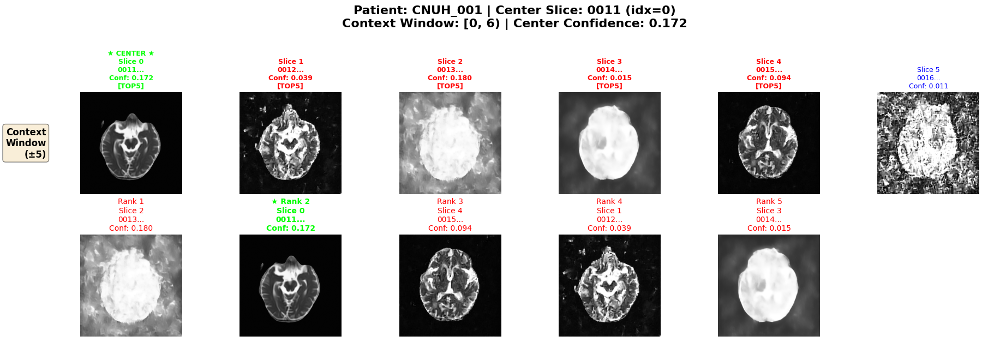

In [68]:
# 각 환자의 여러 슬라이스 상세 시각화
for patient_result in eval_results[:2]:  # 처음 2명만
    n_slices = len(patient_result['results'])
    patient = patient_result['patient']
    
    # 시작, 중간, 끝 슬라이스 시각화
    indices = [0, n_slices // 4, n_slices // 2, n_slices * 3 // 4, n_slices - 1]
    
    for idx in indices:
        fig = plot_detailed_eval(patient_result, idx, figsize=(22, 16))
        plt.savefig(
            Path(CFG["save_dir"]) / "eval_results" / f"{patient}_slice{idx:03d}_detailed.png",
            dpi=150, bbox_inches='tight'
        )
        plt.close()
    
    print(f"✓ Saved {len(indices)} detailed visualizations for {patient}")

print("✓ All detailed visualizations complete")
